# Inicialización de librerias

In [1]:
import math
import time
from dataclasses import dataclass          # se usa en la celda 3 para describir cada problema
from typing import Callable, Optional      # idem: tipos de los campos del problema

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Precision por defecto de TODO tensor que creemos sin especificar dtype.
# float32 y no float64 porque:
#   (a) en 2D el costo lo domina el numero de puntos de colocacion, no el redondeo;
#   (b) en GPUs Blackwell (RTX 50xx) la doble precision esta castigada en hardware,
#       del orden de decenas de veces mas lenta que la simple.
# Si mas adelante el residual debil muestra ruido numerico inexplicable, subir a float64
# es el primer experimento a hacer.
torch.set_default_dtype(torch.float32)

# Dispositivo unico para todo el notebook. Se resuelve UNA vez y se reutiliza.
# Si se deja implicito terminamos con tensores en CPU y red en GPU, y torch aborta
# el entrenamiento con un error de dispositivo a mitad de camino.
COMPUTE_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_random_seed(seed: int = 0) -> None:
    """Fix every random source so a training run can be reproduced exactly.

    Two independent generators are in play: numpy drives anything we do with
    arrays outside the graph, torch drives weight initialisation and the
    Monte-Carlo sampling of collocation points.
    """
    # numpy: lo usamos poco, pero basta un np.random.rand en una grafica para
    # que dos corridas "identicas" dejen de serlo.
    np.random.seed(seed)
    # torch: cubre la inicializacion de pesos Y el muestreo de puntos, que es
    # la fuente de varianza mas fuerte en wPINN (rarefaccion vario entre 0.07 y 0.33
    # entre semillas en los experimentos 1D).
    torch.manual_seed(seed)


# Verificacion de entorno: debe decir algo como "2.14.0+cu128 cuda".
# Si dice "+cpu" la build de torch no trae kernels CUDA y hay que reinstalarla.
print(torch.__version__, COMPUTE_DEVICE)


2.11.0+cu128 cuda


# Definicion del MLP para la solucion de nn

In [2]:
from typing import Sequence   # anchos de capa y cotas: listas o tuplas


class MLP(nn.Module):
    """Multi-layer perceptron: a fully connected feed-forward network R^n -> R^m.

    Deliberately problem-agnostic so it can be reused as a base block for any
    scientific machine learning task. Nothing in here knows about PDEs, space,
    time, or the number of coordinates. In this notebook it plays two roles:
    the solution network u_theta(x, y, t) and the adversarial test network
    phi_eta(x, y, t); only the constructor arguments change between the two.

    Parameters
    ----------
    n_input_features    : dimension of the input vector (3 for (x, y, t)).
    n_output_features   : dimension of the output vector (1 for a scalar law).
    hidden_layer_widths : neurons per hidden layer, one entry per layer
                          (paper: [20] * 6 for u, [10] * 4 for phi).
    activation          : activation module class placed after every hidden
                          layer. Default nn.Tanh, the usual choice for PINNs.
    input_lower_bounds  : optional, one value per input feature. Together with
                          input_upper_bounds rescales inputs to [-1, 1] before
                          the first layer. None disables the rescaling.
    input_upper_bounds  : see input_lower_bounds.
    weight_initialiser  : in-place initialiser applied to every linear layer's
                          weight matrix. Default Glorot / Xavier normal.
    """

    def __init__(
        self,
        n_input_features: int,
        n_output_features: int,
        hidden_layer_widths: Sequence[int],
        activation: type[nn.Module] = nn.Tanh,
        input_lower_bounds: Optional[Sequence[float]] = None,
        input_upper_bounds: Optional[Sequence[float]] = None,
        weight_initialiser: Callable[[torch.Tensor], torch.Tensor] = nn.init.xavier_normal_,
    ) -> None:
        super().__init__()

        # Las cotas son opcionales para que la clase sirva en problemas donde la
        # entrada ya viene normalizada. Se exige que vengan las dos o ninguna:
        # una sola no define un reescalamiento.
        if (input_lower_bounds is None) != (input_upper_bounds is None):
            raise ValueError("input_lower_bounds and input_upper_bounds must be given together")
        if input_lower_bounds is not None and len(input_lower_bounds) != n_input_features:
            raise ValueError("bounds must have one entry per input feature")

        # Cotas guardadas como buffers y NO como parámetros: viajan con la red a la
        # GPU (model.to(device)) y se guardan con state_dict, pero el optimizador
        # no las toca porque no son entrenables. register_buffer acepta None, así
        # que el atributo existe siempre y forward sólo pregunta si es None.
        self.register_buffer(
            "input_lower_bounds",
            None if input_lower_bounds is None else torch.tensor(input_lower_bounds),
        )
        self.register_buffer(
            "input_upper_bounds",
            None if input_upper_bounds is None else torch.tensor(input_upper_bounds),
        )

        # Se arma la lista [Linear, act, Linear, act, ..., Linear] recorriendo los
        # anchos de capa. Con una lista de anchos en vez de (ancho, n_capas) la
        # misma clase admite redes no uniformes, como una que se estrecha hacia
        # la salida, sin cambiar una línea.
        layer_input_widths = [n_input_features, *hidden_layer_widths]
        layers: list[nn.Module] = []
        for input_width, output_width in zip(layer_input_widths[:-1], layer_input_widths[1:]):
            layers += [nn.Linear(input_width, output_width), activation()]
        
        # Última capa sin activación: la salida puede tomar cualquier valor real
        # (por ejemplo -1 en la rarefacción); tanh la recortaría a (-1, 1).
        layers.append(nn.Linear(layer_input_widths[-1], n_output_features))
        self.network = nn.Sequential(*layers)

        # Inicialización de pesos. Por defecto Glorot (Xavier), que es la pensada
        # para tanh: mantiene la varianza de las activaciones de capa en capa, así
        # la red no arranca ni saturada (gradiente cero) ni colapsada en cero. La
        # de PyTorch por defecto (Kaiming uniforme con a=sqrt(5)) está pensada
        # para ReLU. Si alguien pasa activation=nn.ReLU debería pasar también
        # weight_initialiser=nn.init.kaiming_normal_; por eso es argumento.
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                weight_initialiser(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, input_points: torch.Tensor) -> torch.Tensor:
        """Evaluate the network on a batch of inputs.

        Parameters
        ----------
        input_points : tensor of shape (n_points, n_input_features).

        Returns
        -------
        tensor of shape (n_points, n_output_features).
        """
        # Reescalamiento afín de cada coordenada al intervalo [-1, 1] antes de la
        # primera capa, sólo si se dieron cotas. Sin esto, la rarefacción
        # (x en [-5.5, 5.5], t en [0, 2.5]) mete valores de magnitud 5 en tanh y
        # satura la primera capa desde la época cero. Con las cotas dentro de la
        # red, el resto del notebook trabaja en coordenadas físicas y nunca tiene
        # que acordarse de escalar.
        if self.input_lower_bounds is not None:
            input_points = (
                2.0 * (input_points - self.input_lower_bounds)
                / (self.input_upper_bounds - self.input_lower_bounds)
                - 1.0
            )
        return self.network(input_points)


def count_trainable_parameters(model: nn.Module) -> int:
    """Total number of scalar weights the optimiser will update."""
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

In [3]:

# Prueba de humo con los tamaños del paper para la red solución (6 capas de 20) y
# el dominio de la rarefacción. Debe imprimir la forma (5, 1) y 2201 parámetros;
# si sale un error de dispositivo, la red o los puntos no están en COMPUTE_DEVICE.
solution_network = MLP(
    n_input_features=3,
    n_output_features=1,
    hidden_layer_widths=[20] * 6,
    input_lower_bounds=(-5.5, -1.5, 0.0),
    input_upper_bounds=(5.5, 1.5, 2.5),
).to(COMPUTE_DEVICE)

sample_points = torch.rand(5, 3, device=COMPUTE_DEVICE)
print(solution_network(sample_points).shape)
print(count_trainable_parameters(solution_network), "parámetros entrenables")


torch.Size([5, 1])
2201 parámetros entrenables


# Clase para sintetizar el caso de uso en una sola variable llamada ConservationLawProblem

In [4]:
# Aliases de tipo. Todos los campos reciben tensores por lotes y devuelven
# (n_points, 1), para poder restarlos de la salida de la red sin reshape.
#   FluxFunction : H_i(u), recibe u de forma (n_points, 1).
#   InitialField : u_0(spatial_points), recibe (n_points, n_spatial_dimensions).
#   SpaceTimeField : u(spatial_points, time), recibe además time de forma (n_points, 1).
FluxFunction = Callable[[torch.Tensor], torch.Tensor]
InitialField = Callable[[torch.Tensor], torch.Tensor]
SpaceTimeField = Callable[[torch.Tensor, torch.Tensor], torch.Tensor]


@dataclass(frozen=True)
class ConservationLawProblem:
    """One instance of the scalar conservation law u_t + sum_i d/dx_i H_i(u) = 0
    on a box in R^d, for any number d of spatial dimensions.

    Nothing in the class assumes d = 2: the dimension is read from the length
    of the bounds, and every field receives the spatial coordinates as one
    tensor of shape (n_points, d) instead of separate x, y arguments. The four
    cases of the paper are d = 2 instances.

    Attributes
    ----------
    name                    : label used in plots and logs.
    fluxes                  : (H_1, ..., H_d), one flux per spatial direction.
    flux_derivatives        : (H_1', ..., H_d'), needed by the strong residual
                              u_t + sum_i H_i'(u) du/dx_i.
    spatial_lower_bounds    : (x_1_min, ..., x_d_min).
    spatial_upper_bounds    : (x_1_max, ..., x_d_max).
    final_time              : T, the time horizon; time runs over [0, T].
    initial_condition       : u_0(spatial_points).
    boundary_condition      : g(spatial_points, time) on the spatial boundary.
                              None when boundary_condition_type is "periodic".
    boundary_condition_type : "dirichlet" or "periodic", applied to every face.
    exact_solution          : u(spatial_points, time) when known, else None.
    solution_value_range    : (u_min, u_max) attained by the solution. Fixes
                              the colour scale of every plot and the range of
                              the Kruzhkov constants c in the wPINN.
    """

    name: str
    fluxes: tuple[FluxFunction, ...]
    flux_derivatives: tuple[FluxFunction, ...]
    spatial_lower_bounds: tuple[float, ...]
    spatial_upper_bounds: tuple[float, ...]
    final_time: float
    initial_condition: InitialField
    boundary_condition: Optional[SpaceTimeField]
    boundary_condition_type: str
    exact_solution: Optional[SpaceTimeField]
    solution_value_range: tuple[float, float]

    def __post_init__(self) -> None:
        # Se valida en construcción y no al usar, para que un error de dimensión
        # explote aquí con un mensaje claro y no dentro de autograd.
        n_dimensions = len(self.spatial_lower_bounds)
        if len(self.spatial_upper_bounds) != n_dimensions:
            raise ValueError("spatial_lower_bounds and spatial_upper_bounds must have the same length")
        if len(self.fluxes) != n_dimensions or len(self.flux_derivatives) != n_dimensions:
            raise ValueError("one flux and one flux derivative are needed per spatial dimension")
        if self.boundary_condition_type not in ("dirichlet", "periodic"):
            raise ValueError(f"unknown boundary_condition_type {self.boundary_condition_type!r}")
        if (self.boundary_condition is None) != (self.boundary_condition_type == "periodic"):
            raise ValueError("boundary_condition must be None exactly when the boundary is periodic")

    @property
    def n_spatial_dimensions(self) -> int:
        return len(self.spatial_lower_bounds)

    # Las cotas espacio-temporales (x_1, ..., x_d, t) son exactamente lo que pide
    # el MLP de la celda 2, así que se exponen como propiedades para no
    # reconstruir la tupla a mano cada vez que se crea una red.
    @property
    def space_time_lower_bounds(self) -> tuple[float, ...]:
        return (*self.spatial_lower_bounds, 0.0)

    @property
    def space_time_upper_bounds(self) -> tuple[float, ...]:
        return (*self.spatial_upper_bounds, self.final_time)



# Definición de flujos

In [5]:
# --- Flujos ---------------------------------------------------------------
# Se definen como funciones con nombre y no como lambdas porque aparecen en los
# reprs y en los mensajes de error, y "burgers_flux" se lee mejor que "<lambda>".
def burgers_flux(u: torch.Tensor) -> torch.Tensor:
    """H(u) = u^2 / 2, the inviscid Burgers flux (paper eq. 16)."""
    return 0.5 * u**2


def burgers_flux_derivative(u: torch.Tensor) -> torch.Tensor:
    """H'(u) = u."""
    return u


def linear_advection_flux(u: torch.Tensor) -> torch.Tensor:
    """H(u) = u, unit-speed linear advection (paper eq. 20)."""
    return u


def linear_advection_flux_derivative(u: torch.Tensor) -> torch.Tensor:
    """H'(u) = 1, broadcast to the shape of u."""
    return torch.ones_like(u)

# Definicion de condiciones iniciales

In [6]:
# Columnas de la matriz de coordenadas. Nombrarlas evita el "0" y "1" mágicos
# en cada campo y deja claro que el paper trabaja con (x, y) en ese orden.
X_COLUMN = 0
Y_COLUMN = 1


def coordinate_column(spatial_points: torch.Tensor, column: int) -> torch.Tensor:
    """Extract one coordinate as a column tensor of shape (n_points, 1)."""
    # El slice column:column+1 y no [:, column] preserva la segunda dimensión,
    # así el resultado se opera directamente con salidas de red (n_points, 1).
    return spatial_points[:, column : column + 1]


# --- Rarefacción (ec. 17) ---------------------------------------------------
def rarefaction_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = -1 for x <= 0, +1 for x > 0. Independent of y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= 0.0, -1.0, 1.0)


# --- Choque móvil (ec. 18) -------------------------------------------------
MOVING_SHOCK_LEFT_STATE = 1.0
MOVING_SHOCK_RIGHT_STATE = 0.0


def moving_shock_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = 1 for x <= 0, 0 for x > 0. Independent of y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= 0.0, MOVING_SHOCK_LEFT_STATE, MOVING_SHOCK_RIGHT_STATE)


# --- Riemann 2D (ec. 19) ---------------------------------------------------
def riemann_2d_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = 2 in the lower-left quadrant, 3 in the upper-right, 1 elsewhere."""
    x = coordinate_column(spatial_points, X_COLUMN)
    y = coordinate_column(spatial_points, Y_COLUMN)
    # El punto de corte es (0.25, 0.25) y no el centro del cuadrado. Con T = 1/12
    # y velocidad máxima H'(3) = 3, ninguna onda avanza más de 0.25, así que la
    # solución nunca toca el borde x = 1 ni y = 1 y las condiciones de frontera
    # tipo Dirichlet con el dato inicial son consistentes hasta T.
    lower_left = (x < 0.25) & (y < 0.25)
    upper_right = (x > 0.25) & (y > 0.25)
    return torch.where(lower_left, 2.0, torch.where(upper_right, 3.0, 1.0))


# --- Advección periódica (ec. 20-21) ---------------------------------------
def periodic_advection_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = sin^2(pi x) sin^2(pi y), smooth and 1-periodic in x and y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    y = coordinate_column(spatial_points, Y_COLUMN)
    return torch.sin(math.pi * x) ** 2 * torch.sin(math.pi * y) ** 2


# Definicion de condiciones de frontera

In [7]:
# --- Condición de frontera compartida por los tres casos de Burgers ---------
def initial_condition_frozen_in_time(initial_condition: InitialField) -> SpaceTimeField:
    """Build g(spatial_points, t) = u_0(spatial_points): the boundary keeps
    its initial value.

    Valid as long as no wave reaches the spatial boundary before T, which holds
    for the three Burgers cases: the rarefaction fan reaches |x| = 2.5 < 5.5,
    the shock reaches x = 0.25 < 1 and the 2D Riemann waves travel at most
    0.25 from (0.25, 0.25).
    """
    def boundary_condition(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
        return initial_condition(spatial_points)
    return boundary_condition


# Definicion de soluciones exactas para comparacion

In [8]:
# --- Rarefacción (ec. 17) ---------------------------------------------------
def rarefaction_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Entropy solution: a fan u = x / t clipped to [-1, 1].

    Independent of y because the data is, so it is the 1D Burgers fan.
    """
    x = coordinate_column(spatial_points, X_COLUMN)
    # En t = 0 la división x / t es 0/0 o ±inf. Se protege con un t mínimo
    # positivo: para t < 1e-12, x / t queda fuera de [-1, 1] salvo en x = 0, así
    # que clamp devuelve ±1, que coincide con el dato inicial.
    safe_time = torch.clamp(time, min=1e-12)
    return torch.clamp(x / safe_time, min=-1.0, max=1.0)


# --- Choque móvil (ec. 18) -------------------------------------------------
# Velocidad de Rankine-Hugoniot del choque: s = (H(1) - H(0)) / (1 - 0) = 1/2.
# Se calcula desde el flujo y no se escribe 0.5 a mano para que la fórmula
# quede a la vista y para que cambie sola si alguien cambia el flujo.
MOVING_SHOCK_SPEED = (
    burgers_flux(torch.tensor(MOVING_SHOCK_LEFT_STATE)) - burgers_flux(torch.tensor(MOVING_SHOCK_RIGHT_STATE))
).item() / (MOVING_SHOCK_LEFT_STATE - MOVING_SHOCK_RIGHT_STATE)


def moving_shock_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """The jump travels to the right at the Rankine-Hugoniot speed 1/2."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= MOVING_SHOCK_SPEED * time, MOVING_SHOCK_LEFT_STATE, MOVING_SHOCK_RIGHT_STATE)


# --- Advección periódica (ec. 20-21) ---------------------------------------
def periodic_advection_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Pure translation: u(x, y, t) = u_0(x - t, y - t).

    No modulo is needed because sin^2 is already 1-periodic.
    """
    # Se resta t a TODAS las columnas porque la velocidad es (1, 1): el dato se
    # traslada en diagonal.
    return periodic_advection_initial_condition(spatial_points - time)

# Definicion de los problemas a trabajar

In [9]:

# --- Los cuatro problemas del paper -----------------------------------------
# El paper usa el mismo flujo en x y en y, así que se repite la función dos
# veces. Un problema anisótropo pasaría dos flujos distintos.
BURGERS_FLUXES_2D = (burgers_flux, burgers_flux)
BURGERS_FLUX_DERIVATIVES_2D = (burgers_flux_derivative, burgers_flux_derivative)

RAREFACTION_PROBLEM = ConservationLawProblem(
    name="rarefaction",
    fluxes=BURGERS_FLUXES_2D,
    flux_derivatives=BURGERS_FLUX_DERIVATIVES_2D,
    spatial_lower_bounds=(-5.5, -1.5),
    spatial_upper_bounds=(5.5, 1.5),
    final_time=2.5,
    initial_condition=rarefaction_initial_condition,
    boundary_condition=initial_condition_frozen_in_time(rarefaction_initial_condition),
    boundary_condition_type="dirichlet",
    exact_solution=rarefaction_exact_solution,
    solution_value_range=(-1.0, 1.0),
)

MOVING_SHOCK_PROBLEM = ConservationLawProblem(
    name="moving_shock",
    fluxes=BURGERS_FLUXES_2D,
    flux_derivatives=BURGERS_FLUX_DERIVATIVES_2D,
    # El paper escribe y en [1, 1]; es un typo, la figura muestra [-1, 1].
    spatial_lower_bounds=(-1.0, -1.0),
    spatial_upper_bounds=(1.0, 1.0),
    final_time=0.5,
    initial_condition=moving_shock_initial_condition,
    boundary_condition=initial_condition_frozen_in_time(moving_shock_initial_condition),
    boundary_condition_type="dirichlet",
    exact_solution=moving_shock_exact_solution,
    solution_value_range=(0.0, 1.0),
)

RIEMANN_2D_PROBLEM = ConservationLawProblem(
    name="riemann_2d",
    fluxes=BURGERS_FLUXES_2D,
    flux_derivatives=BURGERS_FLUX_DERIVATIVES_2D,
    spatial_lower_bounds=(0.0, 0.0),
    spatial_upper_bounds=(1.0, 1.0),
    final_time=1.0 / 12.0,
    initial_condition=riemann_2d_initial_condition,
    boundary_condition=initial_condition_frozen_in_time(riemann_2d_initial_condition),
    boundary_condition_type="dirichlet",
    # Sin exacta cerrada: aquí sólo se compara cualitativamente con la figura 3.
    exact_solution=None,
    solution_value_range=(1.0, 3.0),
)

PERIODIC_ADVECTION_PROBLEM = ConservationLawProblem(
    name="periodic_advection",
    fluxes=(linear_advection_flux, linear_advection_flux),
    flux_derivatives=(linear_advection_flux_derivative, linear_advection_flux_derivative),
    spatial_lower_bounds=(0.0, 0.0),
    spatial_upper_bounds=(1.0, 1.0),
    final_time=1.0,
    initial_condition=periodic_advection_initial_condition,
    # Periódica: no hay g, la condición es u(0, y, t) = u(1, y, t) y análoga en y.
    boundary_condition=None,
    boundary_condition_type="periodic",
    exact_solution=periodic_advection_exact_solution,
    solution_value_range=(0.0, 1.0),
)

In [10]:
ALL_PROBLEMS = [RAREFACTION_PROBLEM, MOVING_SHOCK_PROBLEM, RIEMANN_2D_PROBLEM, PERIODIC_ADVECTION_PROBLEM]

# Prueba de humo: la exacta en t = 0 debe coincidir con el dato inicial en
# puntos aleatorios del dominio. Si no coincide, alguna de las dos está mal.
for problem in ALL_PROBLEMS:
    if problem.exact_solution is None:
        continue
    lower = torch.tensor(problem.spatial_lower_bounds)
    upper = torch.tensor(problem.spatial_upper_bounds)
    random_spatial_points = lower + (upper - lower) * torch.rand(1000, problem.n_spatial_dimensions)
    time_zero = torch.zeros(1000, 1)
    mismatch = (
        problem.exact_solution(random_spatial_points, time_zero) - problem.initial_condition(random_spatial_points)
    ).abs().max()
    print(f"{problem.name:20s} d = {problem.n_spatial_dimensions}  max |exact(t=0) - u_0| = {mismatch:.1e}")
print("moving shock speed:", MOVING_SHOCK_SPEED)

rarefaction          d = 2  max |exact(t=0) - u_0| = 0.0e+00
moving_shock         d = 2  max |exact(t=0) - u_0| = 0.0e+00
periodic_advection   d = 2  max |exact(t=0) - u_0| = 0.0e+00
moving shock speed: 0.5


# Utilidades para separar y unir espacio y tiempo

In [11]:
# Convención de todo el notebook: un punto espacio-temporal es una fila
# (x_1, ..., x_d, t) y el tiempo es SIEMPRE la última columna. Estas dos
# funciones son el único lugar donde se asume ese orden.
TIME_COLUMN = -1


def split_space_time(space_time_points: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Split (n_points, d + 1) into spatial (n_points, d) and time (n_points, 1)."""
    return space_time_points[:, :TIME_COLUMN], space_time_points[:, TIME_COLUMN:]


def join_space_time(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Inverse of split_space_time: concatenate along the feature axis."""
    return torch.cat([spatial_points, time], dim=1)


# Muestreo uniforme en una caja

In [12]:
def sample_uniform_in_box(
    lower_bounds: Sequence[float],
    upper_bounds: Sequence[float],
    n_points: int,
    device: torch.device = COMPUTE_DEVICE,
) -> torch.Tensor:
    """Draw n_points uniformly at random inside the box [lower, upper] in R^k.

    Returns a tensor of shape (n_points, k). Monte-Carlo sampling and not a
    grid because the PINN loss is an expectation over the domain, and uniform
    random points estimate it without the curse of dimensionality of a grid.
    """
    lower = torch.tensor(lower_bounds, device=device)
    upper = torch.tensor(upper_bounds, device=device)
    # torch.rand da U[0, 1); el mapa afín lo lleva a [lower, upper). Se genera
    # directamente en device para no pagar una copia CPU -> GPU por época.
    unit_samples = torch.rand(n_points, len(lower_bounds), device=device)
    return lower + (upper - lower) * unit_samples


# Puntos interiores, iniciales y de frontera

In [13]:
def sample_interior_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points in the open space-time box, where the PDE residual is enforced."""
    return sample_uniform_in_box(problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points)


def sample_initial_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points on the slice t = 0, where u = u_0 is enforced."""
    spatial_points = sample_uniform_in_box(problem.spatial_lower_bounds, problem.spatial_upper_bounds, n_points)
    time_zero = torch.zeros(n_points, 1, device=spatial_points.device)
    return join_space_time(spatial_points, time_zero)


def sample_boundary_points(
    problem: ConservationLawProblem, n_points: int
) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
    """Points on the lateral boundary (spatial faces x [0, T]).

    Returns (boundary_points, periodic_partner_points). For a Dirichlet
    problem the partner is None. For a periodic problem the partner has the
    same shape as boundary_points and each row is the same point with the
    face coordinate moved to the opposite face, so that the loss can enforce
    u(boundary) = u(partner).
    """
    n_faces = 2 * problem.n_spatial_dimensions
    # Se reparte el presupuesto por igual entre las 2d caras. Si n_points no es
    # múltiplo de 2d se pierde el residuo; es irrelevante frente a miles de puntos.
    n_points_per_face = n_points // n_faces

    boundary_points_per_face = []
    partner_points_per_face = []
    for dimension in range(problem.n_spatial_dimensions):
        for face_bound, opposite_bound in (
            (problem.spatial_lower_bounds[dimension], problem.spatial_upper_bounds[dimension]),
            (problem.spatial_upper_bounds[dimension], problem.spatial_lower_bounds[dimension]),
        ):
            # Se muestrea en toda la caja espacio-temporal y luego se "aplasta"
            # la coordenada de la cara sobre su cota. Es más simple que
            # construir la caja (d-1)-dimensional de cada cara a mano y da la
            # misma distribución uniforme sobre la cara.
            face_points = sample_uniform_in_box(
                problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points_per_face
            )
            face_points[:, dimension] = face_bound
            boundary_points_per_face.append(face_points)

            # El compañero periódico comparte todas las coordenadas (incluido t)
            # y sólo cambia la coordenada de la cara por la cota opuesta.
            partner_points = face_points.clone()
            partner_points[:, dimension] = opposite_bound
            partner_points_per_face.append(partner_points)

    boundary_points = torch.cat(boundary_points_per_face, dim=0)
    if problem.boundary_condition_type == "periodic":
        return boundary_points, torch.cat(partner_points_per_face, dim=0)
    return boundary_points, None


# Puntos interiores, iniciales y de frontera

In [14]:
def sample_interior_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points in the open space-time box, where the PDE residual is enforced."""
    return sample_uniform_in_box(problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points)


def sample_initial_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points on the slice t = 0, where u = u_0 is enforced."""
    spatial_points = sample_uniform_in_box(problem.spatial_lower_bounds, problem.spatial_upper_bounds, n_points)
    time_zero = torch.zeros(n_points, 1, device=spatial_points.device)
    return join_space_time(spatial_points, time_zero)


def sample_boundary_points(
    problem: ConservationLawProblem, n_points: int
) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
    """Points on the lateral boundary (spatial faces x [0, T]).

    Returns (boundary_points, periodic_partner_points). For a Dirichlet
    problem the partner is None. For a periodic problem the partner has the
    same shape as boundary_points and each row is the same point with the
    face coordinate moved to the opposite face, so that the loss can enforce
    u(boundary) = u(partner).
    """
    n_faces = 2 * problem.n_spatial_dimensions
    # Se reparte el presupuesto por igual entre las 2d caras. Si n_points no es
    # múltiplo de 2d se pierde el residuo; es irrelevante frente a miles de puntos.
    n_points_per_face = n_points // n_faces

    boundary_points_per_face = []
    partner_points_per_face = []
    for dimension in range(problem.n_spatial_dimensions):
        for face_bound, opposite_bound in (
            (problem.spatial_lower_bounds[dimension], problem.spatial_upper_bounds[dimension]),
            (problem.spatial_upper_bounds[dimension], problem.spatial_lower_bounds[dimension]),
        ):
            # Se muestrea en toda la caja espacio-temporal y luego se "aplasta"
            # la coordenada de la cara sobre su cota. Es más simple que
            # construir la caja (d-1)-dimensional de cada cara a mano y da la
            # misma distribución uniforme sobre la cara.
            face_points = sample_uniform_in_box(
                problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points_per_face
            )
            face_points[:, dimension] = face_bound
            boundary_points_per_face.append(face_points)

            # El compañero periódico comparte todas las coordenadas (incluido t)
            # y sólo cambia la coordenada de la cara por la cota opuesta.
            partner_points = face_points.clone()
            partner_points[:, dimension] = opposite_bound
            partner_points_per_face.append(partner_points)

    boundary_points = torch.cat(boundary_points_per_face, dim=0)
    if problem.boundary_condition_type == "periodic":
        return boundary_points, torch.cat(partner_points_per_face, dim=0)
    return boundary_points, None


# Paquete de puntos de colocación

In [15]:
@dataclass(frozen=True)
class CollocationPoints:
    """One Monte-Carlo draw of every point set the loss needs.

    All tensors have d + 1 columns (x_1, ..., x_d, t) and live on the compute
    device. periodic_partner_points is None for Dirichlet problems.
    """

    interior_points: torch.Tensor
    initial_points: torch.Tensor
    boundary_points: torch.Tensor
    periodic_partner_points: Optional[torch.Tensor]


def sample_collocation_points(
    problem: ConservationLawProblem,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
) -> CollocationPoints:
    """Draw a fresh set of interior, initial and boundary points for one problem."""
    boundary_points, periodic_partner_points = sample_boundary_points(problem, n_boundary_points)
    return CollocationPoints(
        interior_points=sample_interior_points(problem, n_interior_points),
        initial_points=sample_initial_points(problem, n_initial_points),
        boundary_points=boundary_points,
        periodic_partner_points=periodic_partner_points,
    )


# Prueba de humo del muestreador

In [16]:
# Para cada problema: formas correctas, t = 0 en los iniciales, cada punto de
# frontera toca alguna cara, y en el periódico el compañero está en la cara
# opuesta con el mismo tiempo.
for problem in ALL_PROBLEMS:
    points = sample_collocation_points(problem, n_interior_points=1000, n_initial_points=200, n_boundary_points=400)
    spatial_boundary, time_boundary = split_space_time(points.boundary_points)
    lower = torch.tensor(problem.spatial_lower_bounds, device=spatial_boundary.device)
    upper = torch.tensor(problem.spatial_upper_bounds, device=spatial_boundary.device)
    touches_a_face = ((spatial_boundary == lower) | (spatial_boundary == upper)).any(dim=1).all().item()
    initial_time_is_zero = (split_space_time(points.initial_points)[1] == 0).all().item()
    partner_ok = True
    if points.periodic_partner_points is not None:
        partner_spatial, partner_time = split_space_time(points.periodic_partner_points)
        partner_ok = torch.equal(partner_time, time_boundary) and ((partner_spatial - spatial_boundary).abs().sum(dim=1) > 0).all().item()
    print(
        f"{problem.name:20s} interior {tuple(points.interior_points.shape)} "
        f"initial {tuple(points.initial_points.shape)} boundary {tuple(points.boundary_points.shape)} "
        f"t0={initial_time_is_zero} faces={touches_a_face} partner={partner_ok}"
    )


rarefaction          interior (1000, 3) initial (200, 3) boundary (400, 3) t0=True faces=True partner=True
moving_shock         interior (1000, 3) initial (200, 3) boundary (400, 3) t0=True faces=True partner=True
riemann_2d           interior (1000, 3) initial (200, 3) boundary (400, 3) t0=True faces=True partner=True
periodic_advection   interior (1000, 3) initial (200, 3) boundary (400, 3) t0=True faces=True partner=True


# Derivadas por autograd

In [17]:
def gradient_with_respect_to_inputs(output: torch.Tensor, input_points: torch.Tensor) -> torch.Tensor:
    """d(output)/d(input) for a batch, returned with the shape of input_points.

    output has shape (n_points, 1) and input_points (n_points, k); the result
    is (n_points, k), column j being the partial derivative along input j.
    """
    # Truco estándar: la suma de las salidas tiene gradiente igual al jacobiano
    # fila a fila, porque cada salida depende SÓLO de su propia fila de entrada.
    # create_graph=True deja el grafo vivo para poder derivar otra vez (laplaciano)
    # y para que el gradiente de la pérdida atraviese este cálculo.
    return torch.autograd.grad(output.sum(), input_points, create_graph=True)[0]


def laplacian_in_space(gradient: torch.Tensor, input_points: torch.Tensor, n_spatial_dimensions: int) -> torch.Tensor:
    """Sum of second spatial derivatives d^2 u / dx_i^2, shape (n_points, 1).

    gradient is the output of gradient_with_respect_to_inputs; each column is
    differentiated once more and only the diagonal entry is kept.
    """
    laplacian = torch.zeros_like(gradient[:, :1])
    for dimension in range(n_spatial_dimensions):
        second_derivatives = gradient_with_respect_to_inputs(gradient[:, dimension : dimension + 1], input_points)
        laplacian = laplacian + second_derivatives[:, dimension : dimension + 1]
    return laplacian

# Residual fuerte

In [18]:
def strong_residual(
    network: nn.Module,
    problem: ConservationLawProblem,
    interior_points: torch.Tensor,
    diffusion_coefficient: float,
) -> torch.Tensor:
    """Pointwise residual u_t + sum_i H_i'(u) du/dx_i - epsilon * Laplacian(u).

    Shape (n_points, 1). The diffusion term is the regulariser of the paper's
    "basic PINN + diffusion" variant; epsilon = 0 gives the inviscid law.
    """
    # requires_grad en los PUNTOS y no en la red: queremos derivar u respecto a
    # (x, t), no respecto a los pesos. clone() evita marcar el tensor original
    # que reutilizamos entre épocas.
    interior_points = interior_points.clone().requires_grad_(True)
    solution = network(interior_points)
    gradient = gradient_with_respect_to_inputs(solution, interior_points)

    time_derivative = gradient[:, TIME_COLUMN:]
    # Forma no conservativa H(u)_x = H'(u) u_x. Es válida donde u es suave, que
    # es la hipótesis implícita de todo residual fuerte; en el choque ambas
    # formas están mal y por eso existe la wPINN.
    flux_divergence = torch.zeros_like(solution)
    for dimension, flux_derivative in enumerate(problem.flux_derivatives):
        flux_divergence = flux_divergence + flux_derivative(solution) * gradient[:, dimension : dimension + 1]

    residual = time_derivative + flux_divergence
    # El laplaciano cuesta d pasadas extra de autograd; se omite cuando epsilon = 0.
    if diffusion_coefficient > 0.0:
        residual = residual - diffusion_coefficient * laplacian_in_space(gradient, interior_points, problem.n_spatial_dimensions)
    return residual


# Funcion pédida de PINN fuierte

In [19]:
# Una "penalización" reduce un tensor de discrepancias puntuales (n_points, 1)
# a un escalar. La pérdida no sabe cuál se usa: se le pasa como argumento.
PenaltyFunction = Callable[[torch.Tensor], torch.Tensor]


def mean_squared(values: torch.Tensor) -> torch.Tensor:
    """Mean of the squares: the Monte-Carlo estimate of the squared L2 norm."""
    return torch.mean(values**2)


def mean_absolute(values: torch.Tensor) -> torch.Tensor:
    """Mean of absolute values: the Monte-Carlo estimate of the L1 norm."""
    return torch.mean(values.abs())


def root_mean_squared(values: torch.Tensor) -> torch.Tensor:
    """Square root of mean_squared: same minimiser, gradients of different scale."""
    return torch.sqrt(mean_squared(values))


def strong_pinn_loss_terms(
    network: nn.Module,
    problem: ConservationLawProblem,
    points: CollocationPoints,
    diffusion_coefficient: float,
    penalty: PenaltyFunction = mean_squared,
) -> dict[str, torch.Tensor]:
    """The three terms of the strong PINN loss, unweighted, as a dictionary.

    Keys: "residual", "initial", "boundary". Each term is penalty(mismatch),
    where mismatch is the pointwise vector of what should be zero. The default
    penalty is the mean square (paper eq. 14); any other reduction from
    (n_points, 1) to a scalar can be passed instead.
    """
    residual = strong_residual(network, problem, points.interior_points, diffusion_coefficient)

    initial_spatial_points, _ = split_space_time(points.initial_points)
    initial_mismatch = network(points.initial_points) - problem.initial_condition(initial_spatial_points)

    if problem.boundary_condition_type == "periodic":
        # Periódica: la red debe valer lo mismo en las dos caras opuestas. No
        # hay dato g, se compara la red consigo misma.
        boundary_mismatch = network(points.boundary_points) - network(points.periodic_partner_points)
    else:
        boundary_spatial_points, boundary_time = split_space_time(points.boundary_points)
        boundary_mismatch = network(points.boundary_points) - problem.boundary_condition(boundary_spatial_points, boundary_time)

    return {
        "residual": penalty(residual),
        "initial": penalty(initial_mismatch),
        "boundary": penalty(boundary_mismatch),
    }


def total_loss_from_terms(loss_terms: dict[str, torch.Tensor], boundary_weight: float) -> torch.Tensor:
    """residual + lambda * (initial + boundary), the paper's eq. 15 structure."""
    return loss_terms["residual"] + boundary_weight * (loss_terms["initial"] + loss_terms["boundary"])


# Bucle de entrenamiento

In [20]:
from dataclasses import field   # listas vacías por defecto en el dataclass de historia


@dataclass
class TrainingHistory:
    """Loss terms recorded every epoch, for plotting convergence later."""

    epochs: list[int] = field(default_factory=list)
    residual: list[float] = field(default_factory=list)
    initial: list[float] = field(default_factory=list)
    boundary: list[float] = field(default_factory=list)
    total: list[float] = field(default_factory=list)


def train_strong_pinn(
    network: nn.Module,
    problem: ConservationLawProblem,
    n_epochs: int,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
    boundary_weight: float,
    diffusion_coefficient: float,
    learning_rate: float = 1e-3,
    resample_every_n_epochs: Optional[int] = None,
    log_every_n_epochs: int = 500,
) -> TrainingHistory:
    """Minimise the strong PINN loss with Adam and return the loss history.

    resample_every_n_epochs = None keeps one fixed Monte-Carlo draw, as the
    paper does; an integer redraws the points that often, which trades a bit
    of noise for a much better estimate of the integral over many epochs.
    """
    optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)
    points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)
    history = TrainingHistory()
    start_time = time.perf_counter()

    for epoch in range(1, n_epochs + 1):
        if resample_every_n_epochs is not None and epoch % resample_every_n_epochs == 0:
            points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)

        # set_to_none=True libera la memoria de los gradientes en vez de
        # llenarla de ceros; es más rápido y es el default moderno de torch.
        optimizer.zero_grad(set_to_none=True)
        loss_terms = strong_pinn_loss_terms(network, problem, points, diffusion_coefficient)
        total_loss = total_loss_from_terms(loss_terms, boundary_weight)
        total_loss.backward()
        optimizer.step()

        # .item() sincroniza CPU-GPU; hacerlo una vez por época es aceptable,
        # hacerlo dentro de la pérdida no lo sería.
        history.epochs.append(epoch)
        history.residual.append(loss_terms["residual"].item())
        history.initial.append(loss_terms["initial"].item())
        history.boundary.append(loss_terms["boundary"].item())
        history.total.append(total_loss.item())

        if epoch % log_every_n_epochs == 0 or epoch == n_epochs:
            elapsed_seconds = time.perf_counter() - start_time
            print(
                f"epoch {epoch:6d}  total {history.total[-1]:.3e}  residual {history.residual[-1]:.3e}  "
                f"initial {history.initial[-1]:.3e}  boundary {history.boundary[-1]:.3e}  [{elapsed_seconds:.0f} s]"
            )
    return history


# Prueba de humo de la PINN fuerte

In [21]:
# Entrenamiento corto del choque móvil. No es el presupuesto del paper; sólo
# comprueba que la pérdida baja y que la red se acerca a la exacta.
set_random_seed(0)
smoke_test_problem = MOVING_SHOCK_PROBLEM
smoke_test_network = MLP(
    n_input_features=smoke_test_problem.n_spatial_dimensions + 1,
    n_output_features=1,
    hidden_layer_widths=[20] * 4,
    input_lower_bounds=smoke_test_problem.space_time_lower_bounds,
    input_upper_bounds=smoke_test_problem.space_time_upper_bounds,
).to(COMPUTE_DEVICE)

smoke_test_history = train_strong_pinn(
    smoke_test_network,
    smoke_test_problem,
    n_epochs=1000,
    n_interior_points=8000,
    n_initial_points=1000,
    n_boundary_points=1000,
    boundary_weight=10.0,
    diffusion_coefficient=1e-3,
    log_every_n_epochs=250,
)

# Error L2 relativo contra la exacta en puntos aleatorios del espacio-tiempo.
with torch.no_grad():
    test_points = sample_interior_points(smoke_test_problem, 20000)
    test_spatial, test_time = split_space_time(test_points)
    exact_values = smoke_test_problem.exact_solution(test_spatial, test_time)
    predicted_values = smoke_test_network(test_points)
    relative_l2_error = (torch.norm(predicted_values - exact_values) / torch.norm(exact_values)).item()
print(f"relative L2 error vs exact: {relative_l2_error:.3f}")


epoch    250  total 6.171e-01  residual 3.967e-02  initial 3.670e-02  boundary 2.105e-02  [2 s]
epoch    500  total 4.769e-01  residual 6.487e-02  initial 2.615e-02  boundary 1.505e-02  [4 s]
epoch    750  total 3.199e-01  residual 7.762e-02  initial 1.479e-02  boundary 9.438e-03  [5 s]
epoch   1000  total 2.782e-01  residual 7.600e-02  initial 1.185e-02  boundary 8.378e-03  [7 s]
relative L2 error vs exact: 0.192


# Estilo de figuras

In [22]:
# Hoja de estilo de la skill scientific-figures, copiada al proyecto para que
# el notebook no dependa de la ruta del plugin. Fija tamaños y tipografía; no
# se sobreescriben panel por panel.
plt.style.use("notebook.mplstyle")

# Evaluación en malla

In [23]:
@dataclass(frozen=True)
class GridSnapshot:
    """The solution on a regular 2D grid at one fixed time, as numpy arrays.

    x_axis, y_axis are 1D; predicted and exact have shape (n_y, n_x), the
    matplotlib "xy" convention, so they go straight into pcolormesh(x, y, Z).
    exact is None when the problem has no closed-form solution.
    """

    x_axis: np.ndarray
    y_axis: np.ndarray
    time: float
    predicted: np.ndarray
    exact: Optional[np.ndarray]


def evaluate_on_grid(
    network: nn.Module,
    problem: ConservationLawProblem,
    time: float,
    n_points_per_axis: int = 200,
) -> GridSnapshot:
    """Evaluate the network and the exact solution on a grid at a fixed time.

    Only for d = 2: a colour map needs two spatial axes. The wPINN metrics of
    the next cells use random points instead and stay dimension-agnostic.
    """
    if problem.n_spatial_dimensions != 2:
        raise ValueError("evaluate_on_grid draws colour maps and needs exactly two spatial dimensions")

    x_axis = np.linspace(problem.spatial_lower_bounds[X_COLUMN], problem.spatial_upper_bounds[X_COLUMN], n_points_per_axis)
    y_axis = np.linspace(problem.spatial_lower_bounds[Y_COLUMN], problem.spatial_upper_bounds[Y_COLUMN], n_points_per_axis)
    # indexing="xy" da arreglos (n_y, n_x), que es lo que pcolormesh(x, y, Z)
    # espera. Se mantiene esa convención en TODO el notebook.
    x_grid, y_grid = np.meshgrid(x_axis, y_axis, indexing="xy")

    # numpy genera float64 y la red es float32: sin el dtype explícito torch
    # aborta con "mat1 and mat2 must have the same dtype".
    spatial_points = torch.tensor(
        np.stack([x_grid.ravel(), y_grid.ravel()], axis=1), dtype=torch.get_default_dtype(), device=COMPUTE_DEVICE
    )
    time_column = torch.full((spatial_points.shape[0], 1), time, device=COMPUTE_DEVICE)
    space_time_points = join_space_time(spatial_points, time_column)

    # no_grad: sólo evaluamos, no hace falta grafo y ahorra memoria en mallas grandes.
    with torch.no_grad():
        predicted = network(space_time_points).cpu().numpy().reshape(x_grid.shape)
        exact = None
        if problem.exact_solution is not None:
            exact = problem.exact_solution(spatial_points, time_column).cpu().numpy().reshape(x_grid.shape)
    return GridSnapshot(x_axis=x_axis, y_axis=y_axis, time=time, predicted=predicted, exact=exact)


# Errores relativos L1 y L2

In [24]:
def relative_error(predicted: np.ndarray, exact: np.ndarray, order: int) -> float:
    """||predicted - exact||_p / ||exact||_p on the grid, p = 1 or 2.

    The grid is uniform, so the discrete p-norm is the Monte-Carlo-free
    estimate of the continuous one up to a constant that cancels in the ratio.
    """
    difference = (predicted - exact).ravel()
    return float(np.linalg.norm(difference, ord=order) / np.linalg.norm(exact.ravel(), ord=order))


def final_time_errors(network: nn.Module, problem: ConservationLawProblem) -> dict[str, float]:
    """Relative L1 and L2 errors at t = T, the numbers the paper's figures show."""
    snapshot = evaluate_on_grid(network, problem, time=problem.final_time)
    if snapshot.exact is None:
        return {}
    # L1 y no sólo L2 porque la teoría de Kruzhkov es estabilidad en L1: un
    # choque desplazado delta cuesta O(delta) en L1 pero O(sqrt(delta)) en L2.
    return {
        "relative_l1": relative_error(snapshot.predicted, snapshot.exact, order=1),
        "relative_l2": relative_error(snapshot.predicted, snapshot.exact, order=2),
    }


# Mapas de color: exacta, red y error

In [25]:
# --- Constantes de composición ----------------------------------------------
# Umbral de "dominio ancho": por debajo de esta razón alto/ancho los paneles se
# apilan en columna. La rarefacción (3/11 ≈ 0.27) cae aquí; en fila, cada panel
# quedaría de un centímetro de alto y su colorbar ilegible. Los dominios
# cuadrados (razón 1) van en fila, que es la lectura natural exacta → red → error.
WIDE_DOMAIN_ASPECT_THRESHOLD = 0.5
PANEL_SIZE_INCHES = 3.4
# Rectángulo de la colorbar en coordenadas del eje al que se pega:
# [x0, y0, ancho, alto]. x0 > 1 la pone justo a la derecha del panel; alto = 1
# la hace exactamente tan alta como el panel, que es la razón de usar inset_axes
# y no figure.colorbar(ax=...): esa toma la altura de la celda del gridspec y,
# con aspect="equal", queda más alta que el panel y flotando.
COLORBAR_AXES_RECT = [1.04, 0.0, 0.05, 1.0]
# Niveles de la exacta que se dibujan sobre el panel de la red, como fracción
# del rango de u. Marcan dónde debería estar el frente sin obligar al lector a
# saltar de panel en panel. En un choque los tres coinciden en la misma recta;
# en la rarefacción marcan el interior del abanico.
EXACT_CONTOUR_FRACTIONS = np.array([0.25, 0.5, 0.75])


def colormap_for(problem: ConservationLawProblem) -> str:
    """Diverging map centred on zero if the solution changes sign, sequential otherwise."""
    u_min, u_max = problem.solution_value_range
    # Divergente cuando el campo cruza cero (rarefacción entre -1 y 1): el
    # blanco marca u = 0 y separa las dos fases del abanico. Como el rango es
    # simétrico, vmin/vmax bastan para centrar; no hace falta TwoSlopeNorm.
    # Secuencial en los demás, donde cero no significa nada especial.
    return "RdBu_r" if u_min < 0.0 < u_max else "viridis"


def attach_colorbar(figure: plt.Figure, axis: plt.Axes, mesh, label: str) -> None:
    """Colorbar glued to the right edge of `axis`, with exactly its height."""
    colorbar_axis = axis.inset_axes(COLORBAR_AXES_RECT)
    figure.colorbar(mesh, cax=colorbar_axis, label=label)


def plot_solution_comparison(
    network: nn.Module,
    problem: ConservationLawProblem,
    time: Optional[float] = None,
    method_label: str = "PINN",
    error_value_max: Optional[float] = None,
) -> plt.Figure:
    """Colour maps at one time: exact, network with exact contours, absolute error.

    Value panels share vmin/vmax from problem.solution_value_range. Pass the
    same `error_value_max` to every method you want to compare (PINN, wPINN),
    otherwise each error panel picks its own scale and the comparison lies.
    """
    if time is None:
        time = problem.final_time
    snapshot = evaluate_on_grid(network, problem, time)
    u_min, u_max = problem.solution_value_range
    has_exact = snapshot.exact is not None
    n_panels = 3 if has_exact else 1

    x_extent = problem.spatial_upper_bounds[X_COLUMN] - problem.spatial_lower_bounds[X_COLUMN]
    y_extent = problem.spatial_upper_bounds[Y_COLUMN] - problem.spatial_lower_bounds[Y_COLUMN]
    domain_aspect = y_extent / x_extent
    stack_vertically = domain_aspect < WIDE_DOMAIN_ASPECT_THRESHOLD

    # El tamaño de figura se deriva del panel y no al revés: con aspect="equal"
    # el panel no puede crecer para llenar un alto arbitrario, y el sobrante se
    # convierte en banda blanca. Los sumandos fijos (1.0, 0.6, 0.3, 1.2) son el
    # espacio de títulos, etiquetas y colorbar, medidos con la hoja de estilo.
    if stack_vertically:
        panel_width_inches = 2 * PANEL_SIZE_INCHES
        figure_size = (panel_width_inches + 1.2, n_panels * (panel_width_inches * domain_aspect + 0.6) + 0.3)
        # sharex: los paneles apilados comparten el eje x, se etiqueta una sola vez.
        figure, axes = plt.subplots(n_panels, 1, figsize=figure_size, squeeze=False, sharex=True)
        axes = axes[:, 0]
    else:
        # El 0.72 es la fracción del ancho de celda que ocupa el panel una vez
        # descontados etiqueta y colorbar; sin él la figura sale alta de más.
        figure_size = (n_panels * PANEL_SIZE_INCHES, PANEL_SIZE_INCHES * 0.72 * domain_aspect + 1.0)
        figure, axes = plt.subplots(1, n_panels, figsize=figure_size, squeeze=False, sharey=True)
        axes = axes[0]

    value_panels = [(snapshot.predicted, method_label)]
    if has_exact:
        value_panels.insert(0, (snapshot.exact, "exact"))
    for axis, (field, title) in zip(axes, value_panels):
        mesh = axis.pcolormesh(
            snapshot.x_axis, snapshot.y_axis, field, cmap=colormap_for(problem), vmin=u_min, vmax=u_max, shading="auto"
        )
        axis.set_title(title)
    # Una sola colorbar para los paneles de valor, pegada al último: comparten
    # escala por diseño y repetirla sería redundancia sin información.
    attach_colorbar(figure, axes[len(value_panels) - 1], mesh, "u (dimensionless)")

    if has_exact:
        # Contornos de la EXACTA sobre el panel de la red: anotan dónde debería
        # estar el frente. Negro punteado para que se lea sobre cualquiera de
        # los dos colormaps.
        contour_levels = u_min + EXACT_CONTOUR_FRACTIONS * (u_max - u_min)
        axes[1].contour(
            snapshot.x_axis, snapshot.y_axis, snapshot.exact,
            levels=contour_levels, colors="black", linewidths=0.7, linestyles="--",
        )

        error_field = np.abs(snapshot.predicted - snapshot.exact)
        # Si no se fija desde fuera, la escala del error es la de esta corrida.
        # Para comparar métodos hay que pasar el mismo error_value_max a ambos.
        if error_value_max is None:
            error_value_max = float(error_field.max())
        # El error es no negativo: mapa secuencial propio, con su propia escala,
        # porque su rango no tiene nada que ver con el de u.
        error_mesh = axes[-1].pcolormesh(
            snapshot.x_axis, snapshot.y_axis, error_field,
            cmap="magma", vmin=0.0, vmax=error_value_max, shading="auto",
        )
        # El máximo real va en el título: si la escala se fijó desde fuera, la
        # colorbar ya no lo dice.
        axes[-1].set_title(f"|{method_label} - exact|, max = {error_field.max():.2g}")
        attach_colorbar(figure, axes[-1], error_mesh, "|error| (dimensionless)")

    for axis in axes:
        axis.set_aspect("equal")
    if stack_vertically:
        axes[-1].set_xlabel("x (dimensionless)")
        for axis in axes:
            axis.set_ylabel("y (dimensionless)")
    else:
        for axis in axes:
            axis.set_xlabel("x (dimensionless)")
        axes[0].set_ylabel("y (dimensionless)")
    # El nombre interno lleva guion bajo; en el título se lee como prosa.
    figure.suptitle(f"{problem.name.replace('_', ' ')}, t = {time:.3g}")
    return figure

# Historia de entrenamiento

In [26]:
def plot_training_history(history: TrainingHistory, title: str = "training loss") -> plt.Figure:
    """Loss terms versus epoch on a log axis, one line per term."""
    figure, axis = plt.subplots()
    # Escala log porque los términos caen varios órdenes de magnitud; en lineal
    # todo se aplasta contra cero después de las primeras épocas.
    axis.semilogy(history.epochs, history.total, label="total", linestyle="-")
    axis.semilogy(history.epochs, history.residual, label="residual", linestyle="--")
    axis.semilogy(history.epochs, history.initial, label="initial", linestyle=":")
    axis.semilogy(history.epochs, history.boundary, label="boundary", linestyle="-.")
    axis.set_xlabel("epoch")
    axis.set_ylabel("loss (log scale, dimensionless)")
    axis.set_title(title)
    axis.legend()
    return figure


{'relative_l1': 0.1115705668926239, 'relative_l2': 0.21194636821746826}


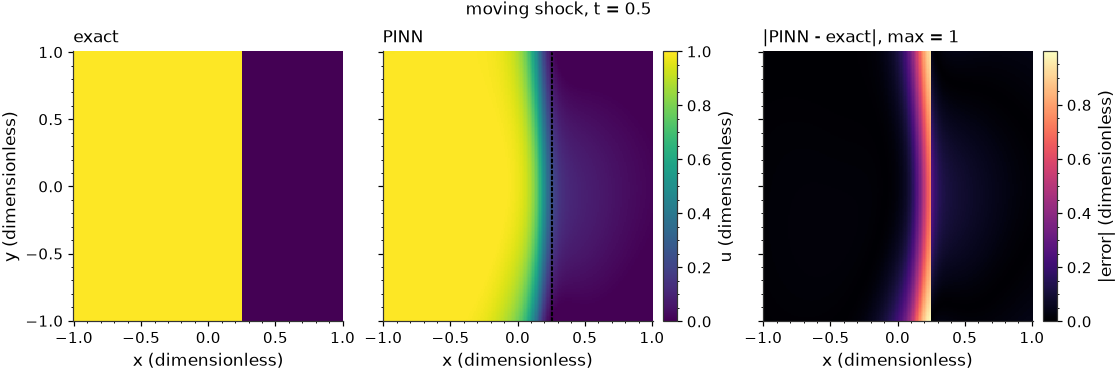

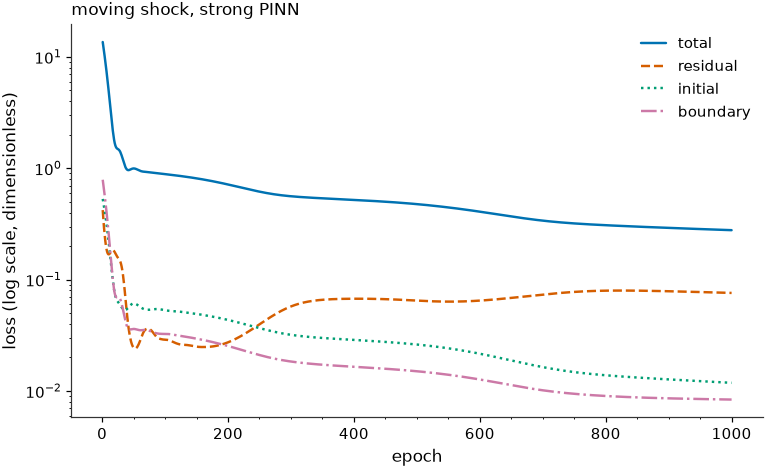

In [27]:
print(final_time_errors(smoke_test_network, smoke_test_problem))
plot_solution_comparison(smoke_test_network, smoke_test_problem)
plot_training_history(smoke_test_history, title="moving shock, strong PINN")
plt.show()


**Figura.** Choque móvil de Burgers 2D en `t = 0.5`, PINN fuerte de la prueba de
humo. Izquierda: solución exacta. Centro: red; las líneas punteadas son los
contornos de la exacta a `u = 0.25, 0.5, 0.75`, que en el choque coinciden en
`x = t/2 = 0.25`. Ambos paneles comparten escala `u ∈ [0, 1]`. Derecha: error
absoluto con su propia escala; el máximo se concentra en el frente, como
corresponde a un choque suavizado. Los errores relativos L1 y L2 en `t = T` se
imprimen arriba de la figura.

# Red de funciones test



In [28]:
import torch.nn.functional as functional   # softplus, una de las transformaciones de rango

# Dos "ganchos" definen la estructura de phi a partir del MLP interno xi:
#   phi(x, t) = window(x, t) * range_transform(xi(x, t))
# range_transform actúa sobre el VALOR (impone signo, cota, etc.);
# window actúa sobre el DOMINIO (dónde phi se anula). Cualquiera puede ser None.
# El paper no impone ninguno; De Ryck usa softplus + campana polinómica.
RangeTransform = Callable[[torch.Tensor], torch.Tensor]
WindowFunction = Callable[[torch.Tensor], torch.Tensor]


class TestFunctionNetwork(nn.Module):
    """Adversarial test function phi(x, t) of the weak formulation.

        phi(x, t) = window(x, t) * range_transform(xi(x, t))

    xi is a plain MLP (the paper: 4 layers of 10 neurons). range_transform
    shapes the values (e.g. softplus for phi > 0) and window shapes the
    support (e.g. a bump vanishing on the spatial boundary). None for both
    reproduces the paper literally. Any callable with the right signature
    can be plugged in, so alternative constraints are a one-line change.

    Parameters
    ----------
    problem             : gives the box and the input dimension d + 1.
    hidden_layer_widths : layers of the inner MLP.
    range_transform     : (n_points, 1) -> (n_points, 1), applied to xi. None = identity.
    window              : (n_points, d + 1) -> (n_points, 1), multiplies the result. None = 1.
    """

    def __init__(
        self,
        problem: ConservationLawProblem,
        hidden_layer_widths: Sequence[int],
        range_transform: Optional[RangeTransform] = None,
        window: Optional[WindowFunction] = None,
    ) -> None:
        super().__init__()
        self.range_transform = range_transform
        self.window = window
        self.inner_network = MLP(
            n_input_features=problem.n_spatial_dimensions + 1,
            n_output_features=1,
            hidden_layer_widths=hidden_layer_widths,
            input_lower_bounds=problem.space_time_lower_bounds,
            input_upper_bounds=problem.space_time_upper_bounds,
        )

    def forward(self, space_time_points: torch.Tensor) -> torch.Tensor:
        test_values = self.inner_network(space_time_points)
        if self.range_transform is not None:
            test_values = self.range_transform(test_values)
        if self.window is not None:
            test_values = self.window(space_time_points) * test_values
        return test_values

    def reset_parameters(self) -> None:
        """Re-draw the inner weights. De Ryck (Algorithm 1) restarts the
        adversary every epoch so it does not get stuck in a stale maximum."""
        for layer in self.inner_network.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)


# Transformaciones de rango para phi




In [29]:
# softplus(z) = ln(1 + e^z) > 0, suave, derivada nunca nula. Es la elección
# de De Ryck para phi >= 0: la condición de Kruzhkov es una desigualdad
# probada contra phi >= 0; con phi de signo libre, -phi la convierte en
# igualdad y la pérdida castiga la disipación legítima de un choque físico.
positive_by_softplus: RangeTransform = functional.softplus


def positive_by_square(values: torch.Tensor) -> torch.Tensor:
    """phi = xi^2 >= 0. Can touch zero, unlike softplus; gradient vanishes there."""
    return values**2


def bounded_by_tanh(values: torch.Tensor) -> torch.Tensor:
    """phi in (-1, 1). Caps the amplitude instead of the sign, an alternative
    to the H^-1 normalisation for taming the adversary."""
    return torch.tanh(values)


# Ventanas de soporte para phi




In [30]:
def polynomial_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """omega(x) = prod_i 4 (x_i - a_i)(b_i - x_i) / (b_i - a_i)^2: 1 at the
    centre of the box, 0 on every spatial face. Ignores t."""
    lower = torch.tensor(problem.spatial_lower_bounds, device=COMPUTE_DEVICE)
    upper = torch.tensor(problem.spatial_upper_bounds, device=COMPUTE_DEVICE)
    extents = upper - lower

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        spatial_points, _ = split_space_time(space_time_points)
        # Se anula en la frontera espacial: justifica integrar por partes en x
        # sin términos de borde. El 4/(b-a)^2 normaliza el máximo a 1.
        bump_per_axis = 4.0 * (spatial_points - lower) * (upper - spatial_points) / extents**2
        return torch.prod(bump_per_axis, dim=1, keepdim=True)

    return window


def sine_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """omega(x) = prod_i sin(pi (x_i - a_i) / (b_i - a_i)): same zeros as the
    polynomial bump but flatter near the centre, so phi is less concentrated."""
    lower = torch.tensor(problem.spatial_lower_bounds, device=COMPUTE_DEVICE)
    upper = torch.tensor(problem.spatial_upper_bounds, device=COMPUTE_DEVICE)
    extents = upper - lower

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        spatial_points, _ = split_space_time(space_time_points)
        return torch.prod(torch.sin(math.pi * (spatial_points - lower) / extents), dim=1, keepdim=True)

    return window


def space_time_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """Polynomial bump in space times t (T - t): phi also vanishes at t = 0 and
    t = T, the choice when integrating by parts in time as well."""
    spatial_window = polynomial_bump_window(problem)
    final_time = problem.final_time

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        _, time = split_space_time(space_time_points)
        return spatial_window(space_time_points) * 4.0 * time * (final_time - time) / final_time**2

    return window


# Constantes de Kruzhkov y volumen del dominio




In [31]:
def kruzhkov_constants(problem: ConservationLawProblem, n_constants: int, margin_fraction: float = 0.25) -> torch.Tensor:
    """Grid of constants c for the Kruzhkov entropies |u - c|, shape (1, n_constants).

    Spans the solution range extended by margin_fraction on both sides.
    """
    u_min, u_max = problem.solution_value_range
    margin = margin_fraction * (u_max - u_min)
    # El conjunto DEBE salirse del rango de u por los dos lados: con c < min u
    # el residual de entropía es el residual de la ecuación, y con c > max u es
    # su negativo. Pedir ReLU = 0 en ambos extremos equivale a imponer la EDP;
    # los c interiores añaden la desigualdad que descarta el choque de expansión.
    return torch.linspace(u_min - margin, u_max + margin, n_constants, device=COMPUTE_DEVICE).reshape(1, -1)


def space_time_volume(problem: ConservationLawProblem) -> float:
    """|Omega| * T, the constant that turns a Monte-Carlo mean into an integral."""
    spatial_volume = math.prod(
        upper - lower for lower, upper in zip(problem.spatial_lower_bounds, problem.spatial_upper_bounds)
    )
    return spatial_volume * problem.final_time


# Entradas del residual débil

In [32]:
def evaluate_with_gradient(network: nn.Module, points: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Return (values, gradient) of a scalar network at the points.

    values has shape (n_points, 1) and gradient (n_points, d + 1). Used for
    both the solution network and the test network.
    """
    points = points.clone().requires_grad_(True)
    values = network(points)
    return values, gradient_with_respect_to_inputs(values, points)


@dataclass(frozen=True)
class WeakResidualInputs:
    """Everything a weak residual term may need, evaluated at the interior points.

    solution, test_values      : (n_points, 1)
    solution_gradient, test_gradient : (n_points, d + 1), time in the last column
    constants                  : (1, n_constants), the Kruzhkov grid
    """

    problem: ConservationLawProblem
    solution: torch.Tensor
    solution_gradient: torch.Tensor
    test_values: torch.Tensor
    test_gradient: torch.Tensor
    constants: torch.Tensor

    # Cantidades derivadas que usan varios términos, calculadas una vez.
    @property
    def sign_u_minus_c(self) -> torch.Tensor:
        """sign(u - c), shape (n_points, n_constants) by broadcasting."""
        return torch.sign(self.solution - self.constants)

    @property
    def time_derivative(self) -> torch.Tensor:
        return self.solution_gradient[:, TIME_COLUMN:]

    @property
    def spatial_solution_gradient(self) -> torch.Tensor:
        return self.solution_gradient[:, : self.problem.n_spatial_dimensions]

    @property
    def spatial_test_gradient(self) -> torch.Tensor:
        return self.test_gradient[:, : self.problem.n_spatial_dimensions]


# Términos del residual débil: L0, L1, L2 del paper




In [33]:
# Un término del residual débil es cualquier función de las entradas que
# devuelva el integrando puntual, forma (n_points, n_constants). El residual
# es |D| veces la media de la suma de los términos elegidos. Así L0, L1 y L2
# del paper son listas de términos, y un término nuevo es una función nueva.
WeakResidualTerm = Callable[[WeakResidualInputs], torch.Tensor]


def kruzhkov_term(inputs: WeakResidualInputs) -> torch.Tensor:
    """L0, paper eq. (10): phi * s * u_t - sum_i Q_i * d_i phi, Q_i = s (H_i(u) - H_i(c)).

    Integrated by parts in space only; the time derivative stays on |u - c|
    as in De Ryck. Non-positive for an entropy solution and any phi >= 0.
    """
    sign = inputs.sign_u_minus_c
    entropy_flux_divergence = torch.zeros_like(sign)
    for dimension, flux in enumerate(inputs.problem.fluxes):
        entropy_flux = sign * (flux(inputs.solution) - flux(inputs.constants))
        entropy_flux_divergence = entropy_flux_divergence + entropy_flux * inputs.test_gradient[:, dimension : dimension + 1]
    return inputs.test_values * sign * inputs.time_derivative - entropy_flux_divergence


def entropy_rate_term(inputs: WeakResidualInputs) -> torch.Tensor:
    """L1 - L0, paper eq. (11): d/dt of the total Kruzhkov entropy, s * u_t.

    Integrated over space-time it equals int |u(T) - c| - |u_0 - c| dx, the
    net entropy produced; an entropy solution does not produce any.
    """
    # Sin phi: es la tasa de la entropía total, no un residual probado contra
    # una función test. Por eso el paper lo escribe fuera de la integral con phi.
    return inputs.sign_u_minus_c * inputs.time_derivative


def weak_diffusion_term(diffusion_coefficient: float) -> WeakResidualTerm:
    """L2 - L1, paper eq. (12): + eps * s * grad u . grad phi.

    The viscous law u_t + div H(u) - eps Lap u = 0 tested against phi and
    integrated by parts turns -eps Lap u into +eps grad u . grad phi; the
    sign s makes it the diffusion of |u - c|. The paper writes it with a
    minus because its L0 carries a global minus in front.
    """
    def term(inputs: WeakResidualInputs) -> torch.Tensor:
        return diffusion_coefficient * inputs.sign_u_minus_c * torch.sum(
            inputs.spatial_solution_gradient * inputs.spatial_test_gradient, dim=1, keepdim=True
        )
    return term


# Las tres pérdidas del paper como listas de términos. Cualquier otra
# combinación, o un término propio, se arma igual.
def paper_loss_terms(level: int, diffusion_coefficient: float = 1e-3) -> list[WeakResidualTerm]:
    """L0, L1 or L2 of the paper (eqs. 10-12) as a list of residual terms."""
    terms: list[WeakResidualTerm] = [kruzhkov_term]
    if level >= 1:
        terms.append(entropy_rate_term)
    if level >= 2:
        terms.append(weak_diffusion_term(diffusion_coefficient))
    return terms


# Residual débil y agregación sobre c




In [34]:
def weak_entropy_residual(
    inputs: WeakResidualInputs,
    residual_terms: Sequence[WeakResidualTerm],
    signed: bool = False,
) -> tuple[torch.Tensor, torch.Tensor]:
    """R(c) = |D| mean( sum of the chosen terms ) for every constant c at once,
    and its normalised penalty J(c) = ReLU(R(c))^2 / ||grad phi||^2 (eq. 13).

    Returns (J, R), both of shape (n_constants,). With signed=True, J is
    R |R| / ||grad phi||^2: same value where R > 0, negative where R < 0, so
    the adversary keeps a gradient before it finds any violation.
    """
    volume = space_time_volume(inputs.problem)
    integrand = sum(term(inputs) for term in residual_terms)
    residual_per_constant = volume * torch.mean(integrand, dim=0)

    # Normalización H^-1 discreta: sin ella la adversaria maximiza escalando
    # phi, y el residual crece sin cota sin decir nada sobre u.
    test_gradient_norm_squared = volume * torch.mean(torch.sum(inputs.spatial_test_gradient**2, dim=1))
    small_number_to_avoid_division_by_zero = 1e-12
    if signed:
        numerator = residual_per_constant * residual_per_constant.abs()
    else:
        numerator = torch.relu(residual_per_constant) ** 2
    return numerator / (test_gradient_norm_squared + small_number_to_avoid_division_by_zero), residual_per_constant


def aggregate_over_constants(penalties_per_constant: torch.Tensor, mode: str = "max") -> torch.Tensor:
    """Collapse J(c) over the grid of constants into one scalar.

    "max" is De Ryck's remark 4.3: the entropy condition must hold for every
    c, so the worst one drives the loss. "mean" is gentler but, in the 1D
    experiments, averaging let the shock smear out; keep "max" by default.
    """
    if mode == "max":
        return penalties_per_constant.max()
    if mode == "mean":
        return penalties_per_constant.mean()
    raise ValueError(f"unknown aggregation mode {mode!r}")


# Prueba de humo del residual débil




In [35]:
# Sobre la PINN fuerte ya entrenada del choque móvil, el residual débil debe ser
# pequeño para todo c. Se prueban la phi literal del paper y la de De Ryck.
smoke_test_constants = kruzhkov_constants(smoke_test_problem, n_constants=8)
smoke_test_points = sample_interior_points(smoke_test_problem, 4000)
solution, solution_gradient = evaluate_with_gradient(smoke_test_network, smoke_test_points)

test_network_variants = {
    "paper": TestFunctionNetwork(smoke_test_problem, hidden_layer_widths=[10] * 4),
    "de_ryck": TestFunctionNetwork(
        smoke_test_problem,
        hidden_layer_widths=[10] * 4,
        range_transform=positive_by_softplus,
        window=polynomial_bump_window(smoke_test_problem),
    ),
}
print("constants:", smoke_test_constants.ravel().cpu().numpy().round(2))
for variant_name, test_network in test_network_variants.items():
    test_network = test_network.to(COMPUTE_DEVICE)
    test_values, test_gradient = evaluate_with_gradient(test_network, smoke_test_points)
    inputs = WeakResidualInputs(
        smoke_test_problem, solution, solution_gradient, test_values, test_gradient, smoke_test_constants
    )
    # L2 del paper: Kruzhkov + tasa de entropía + difusión débil con eps = 1e-3.
    penalties, residuals = weak_entropy_residual(inputs, paper_loss_terms(2, diffusion_coefficient=1e-3))
    print(f"[{variant_name}] residual per constant:", residuals.detach().cpu().numpy().round(4))
    print(f"[{variant_name}] worst penalty over c:", aggregate_over_constants(penalties).item())


constants: [-0.25 -0.04  0.18  0.39  0.61  0.82  1.04  1.25]
[paper] residual per constant: [ 0.2565  0.2377  0.0691 -0.0792 -0.2048 -0.3365 -0.5663 -0.7164]
[paper] worst penalty over c: 0.5122867822647095
[de_ryck] residual per constant: [ 0.336   0.3352  0.1134 -0.0483 -0.1401 -0.1971 -0.3499 -0.3566]
[de_ryck] worst penalty over c: 0.0803714394569397


# Términos de datos, compartidos por PINN y wPINN




In [36]:
def data_loss_terms(
    network: nn.Module,
    problem: ConservationLawProblem,
    points: CollocationPoints,
    penalty: PenaltyFunction = mean_squared,
) -> dict[str, torch.Tensor]:
    """Initial and boundary mismatch penalties, keys "initial" and "boundary".

    Identical for the strong and the weak formulation: only the PDE term
    changes between them. strong_pinn_loss_terms could call this too.
    """
    initial_spatial_points, _ = split_space_time(points.initial_points)
    initial_mismatch = network(points.initial_points) - problem.initial_condition(initial_spatial_points)

    if problem.boundary_condition_type == "periodic":
        # Periódica: la red debe valer lo mismo en las dos caras opuestas.
        boundary_mismatch = network(points.boundary_points) - network(points.periodic_partner_points)
    else:
        boundary_spatial_points, boundary_time = split_space_time(points.boundary_points)
        boundary_mismatch = network(points.boundary_points) - problem.boundary_condition(boundary_spatial_points, boundary_time)

    return {"initial": penalty(initial_mismatch), "boundary": penalty(boundary_mismatch)}


# Paso de ascenso de la adversaria




In [37]:
def adversary_ascent_step(
    test_network: TestFunctionNetwork,
    test_optimizer: torch.optim.Optimizer,
    interior_points: torch.Tensor,
    solution: torch.Tensor,
    solution_gradient: torch.Tensor,
    problem: ConservationLawProblem,
    constants: torch.Tensor,
    residual_terms: Sequence[WeakResidualTerm],
    aggregation_mode: str,
) -> float:
    """One gradient-ascent step on the test network, u frozen. Returns the
    (signed) penalty reached, clipped at zero for logging."""
    test_optimizer.zero_grad(set_to_none=True)
    test_values, test_gradient = evaluate_with_gradient(test_network, interior_points)
    # signed=True: la adversaria necesita gradiente aunque todavía no haya
    # encontrado una violación (donde ReLU daría cero). u llega ya desprendida
    # del grafo (detach) para que este paso NO mueva los pesos de la solución.
    inputs = WeakResidualInputs(problem, solution, solution_gradient, test_values, test_gradient, constants)
    penalties, _ = weak_entropy_residual(inputs, residual_terms, signed=True)
    objective = aggregate_over_constants(penalties, aggregation_mode)
    # Ascenso = descenso sobre el negativo. Cambiar el signo es más explícito
    # que el modo maximize de Adam.
    (-objective).backward()
    test_optimizer.step()
    return max(objective.item(), 0.0)


# Bucle min-max




In [38]:
@dataclass
class WeakTrainingHistory:
    """Loss terms recorded every epoch of the min-max training."""

    epochs: list[int] = field(default_factory=list)
    weak_residual: list[float] = field(default_factory=list)
    adversary_objective: list[float] = field(default_factory=list)
    initial: list[float] = field(default_factory=list)
    boundary: list[float] = field(default_factory=list)
    total: list[float] = field(default_factory=list)


def train_weak_pinn(
    network: nn.Module,
    test_network: TestFunctionNetwork,
    problem: ConservationLawProblem,
    n_epochs: int,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
    n_kruzhkov_constants: int,
    boundary_weight: float,
    residual_terms: Sequence[WeakResidualTerm],
    n_adversary_steps: int = 5,
    n_solution_steps: int = 1,
    learning_rate: float = 1e-3,
    adversary_learning_rate: float = 1e-2,
    reset_adversary_every_n_epochs: Optional[int] = 1,
    resample_every_n_epochs: Optional[int] = None,
    penalty: PenaltyFunction = mean_squared,
    aggregation_mode: str = "max",
    log_every_n_epochs: int = 100,
) -> WeakTrainingHistory:
    """De Ryck's Algorithm 1 for the paper's loss (eq. 15).

    residual_terms chooses the weak residual: paper_loss_terms(0), (1) or (2)
    for L0, L1, L2 of the paper, or any list of WeakResidualTerm.
    Each epoch: optionally re-draw the adversary, run n_adversary_steps of
    ascent on phi with u frozen, then n_solution_steps of descent on u with
    phi frozen. reset_adversary_every_n_epochs = 1 is De Ryck's choice; None
    never resets and lets the adversary drift across epochs.
    """
    solution_optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)
    test_optimizer = torch.optim.Adam(test_network.parameters(), lr=adversary_learning_rate)
    constants = kruzhkov_constants(problem, n_kruzhkov_constants)
    points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)
    history = WeakTrainingHistory()
    start_time = time.perf_counter()

    for epoch in range(1, n_epochs + 1):
        if resample_every_n_epochs is not None and epoch % resample_every_n_epochs == 0:
            points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)
        if reset_adversary_every_n_epochs is not None and epoch % reset_adversary_every_n_epochs == 0:
            test_network.reset_parameters()
            # Adam guarda momentos por parámetro; tras reiniciar los pesos esos
            # momentos son basura, así que se reinicia también el optimizador.
            test_optimizer = torch.optim.Adam(test_network.parameters(), lr=adversary_learning_rate)

        # --- max sobre phi: u congelada ---
        solution, solution_gradient = evaluate_with_gradient(network, points.interior_points)
        solution, solution_gradient = solution.detach(), solution_gradient.detach()
        adversary_objective = 0.0
        for _ in range(n_adversary_steps):
            adversary_objective = adversary_ascent_step(
                test_network, test_optimizer, points.interior_points, solution, solution_gradient,
                problem, constants, residual_terms, aggregation_mode,
            )

        # --- min sobre theta: phi congelada ---
        test_values, test_gradient = evaluate_with_gradient(test_network, points.interior_points)
        test_values, test_gradient = test_values.detach(), test_gradient.detach()
        for _ in range(n_solution_steps):
            solution_optimizer.zero_grad(set_to_none=True)
            solution, solution_gradient = evaluate_with_gradient(network, points.interior_points)
            inputs = WeakResidualInputs(problem, solution, solution_gradient, test_values, test_gradient, constants)
            penalties, _ = weak_entropy_residual(inputs, residual_terms)
            weak_residual_loss = aggregate_over_constants(penalties, aggregation_mode)
            data_terms = data_loss_terms(network, problem, points, penalty)
            total_loss = weak_residual_loss + boundary_weight * (data_terms["initial"] + data_terms["boundary"])
            total_loss.backward()
            solution_optimizer.step()

        history.epochs.append(epoch)
        history.weak_residual.append(weak_residual_loss.item())
        history.adversary_objective.append(adversary_objective)
        history.initial.append(data_terms["initial"].item())
        history.boundary.append(data_terms["boundary"].item())
        history.total.append(total_loss.item())

        if epoch % log_every_n_epochs == 0 or epoch == n_epochs:
            elapsed_seconds = time.perf_counter() - start_time
            print(
                f"epoch {epoch:6d}  total {history.total[-1]:.3e}  weak {history.weak_residual[-1]:.3e}  "
                f"adversary {adversary_objective:.3e}  initial {history.initial[-1]:.3e}  "
                f"boundary {history.boundary[-1]:.3e}  [{elapsed_seconds:.0f} s]"
            )
    return history


# Prueba de humo de la wPINN




epoch    100  total 9.111e-01  weak 2.064e-02  adversary 9.667e-03  initial 5.415e-02  boundary 3.489e-02  [3 s]
epoch    200  total 4.198e-01  weak 1.549e-02  adversary 1.402e-02  initial 2.580e-02  boundary 1.463e-02  [6 s]
epoch    300  total 3.204e-01  weak 1.570e-02  adversary 1.466e-02  initial 1.925e-02  boundary 1.122e-02  [9 s]
epoch    400  total 2.182e-01  weak 8.327e-03  adversary 6.705e-03  initial 1.355e-02  boundary 7.430e-03  [11 s]
epoch    500  total 1.348e-01  weak 1.241e-02  adversary 1.046e-02  initial 8.058e-03  boundary 4.181e-03  [14 s]
{'relative_l1': 0.2086908519268036, 'relative_l2': 0.3833005428314209}


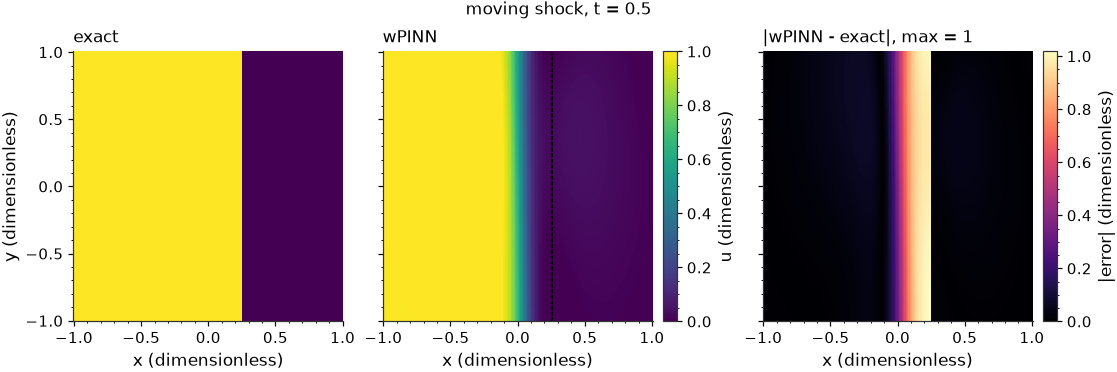

In [39]:
# Choque móvil con presupuesto reducido y la phi de De Ryck. Debe correr en
# menos de un minuto y dejar un error L1 comparable al de la PINN fuerte.
set_random_seed(0)
weak_smoke_problem = MOVING_SHOCK_PROBLEM
weak_smoke_network = MLP(
    n_input_features=weak_smoke_problem.n_spatial_dimensions + 1,
    n_output_features=1,
    hidden_layer_widths=[20] * 6,
    input_lower_bounds=weak_smoke_problem.space_time_lower_bounds,
    input_upper_bounds=weak_smoke_problem.space_time_upper_bounds,
).to(COMPUTE_DEVICE)
weak_smoke_test_network = TestFunctionNetwork(
    weak_smoke_problem,
    hidden_layer_widths=[10] * 4,
    range_transform=positive_by_softplus,
    window=polynomial_bump_window(weak_smoke_problem),
).to(COMPUTE_DEVICE)

weak_smoke_history = train_weak_pinn(
    weak_smoke_network,
    weak_smoke_test_network,
    weak_smoke_problem,
    n_epochs=500,
    n_interior_points=8000,
    n_initial_points=1000,
    n_boundary_points=1000,
    n_kruzhkov_constants=8,
    boundary_weight=10.0,
    # L2 del paper; cambiar a paper_loss_terms(0) o (1) para ver el efecto de
    # cada término, o pasar una lista propia de WeakResidualTerm.
    residual_terms=paper_loss_terms(2, diffusion_coefficient=1e-3),
    log_every_n_epochs=100,
)

print(final_time_errors(weak_smoke_network, weak_smoke_problem))
plot_solution_comparison(weak_smoke_network, weak_smoke_problem, method_label="wPINN")
plt.show()


# Ensamble de reentrenamientos




In [40]:
@dataclass(frozen=True)
class EnsembleMember:
    """One retraining of the same configuration with its own random seed.

    training_history is whatever the trainer returned (TrainingHistory for
    the strong PINN, WeakTrainingHistory for the wPINN). Both expose .total,
    which is what a loss-based selection of hyperparameters needs later.
    """

    seed: int
    network: nn.Module
    training_history: TrainingHistory | WeakTrainingHistory


# Un entrenador de miembro no recibe argumentos: construye una red nueva, la
# entrena y devuelve (red, historia). Todo lo que cambia entre miembros lo
# controla la semilla, que se fija fuera: inicialización de pesos y sorteo
# Monte Carlo de los puntos de colocación.
MemberTrainer = Callable[[], tuple[nn.Module, TrainingHistory | WeakTrainingHistory]]


def train_ensemble(train_one_member: MemberTrainer, seeds: Sequence[int]) -> list[EnsembleMember]:
    """Retrain the same configuration once per seed and collect the members.

    This is De Ryck's ensemble: the wPINN is a noisy min-max game and a single
    run can land far from the entropy solution, so several retrainings are
    averaged. The paper of Abreu et al. argues that its diffusion term plays
    this role with a single network; this function is what that claim is
    compared against.
    """
    members = []
    for seed in seeds:
        # La semilla se fija AQUÍ y no dentro del entrenador, para que el
        # entrenador no sepa que forma parte de un ensamble y sea el mismo
        # código que se usa para una corrida suelta.
        set_random_seed(seed)
        print(f"--- ensemble member, seed {seed} ---")
        network, training_history = train_one_member()
        members.append(EnsembleMember(seed=seed, network=network, training_history=training_history))
    return members


# Media y desviación del ensamble como una red más




In [41]:
class EnsembleStatistic(nn.Module):
    """Mean or standard deviation across the members, exposed as a network.

    It maps (n_points, d + 1) to (n_points, 1) like any solution network, so
    evaluate_on_grid, final_time_errors and plot_solution_comparison work on
    the ensemble mean with no changes: the ensemble is "just another u".

    Parameters
    ----------
    members   : output of train_ensemble.
    statistic : "mean" (the ensemble prediction) or "std" (its spread).
    """

    def __init__(self, members: Sequence[EnsembleMember], statistic: str = "mean") -> None:
        super().__init__()
        if statistic not in ("mean", "std"):
            raise ValueError(f"unknown statistic {statistic!r}, use 'mean' or 'std'")
        self.statistic = statistic
        # nn.ModuleList y no una lista de Python: así .to(device), .eval() y
        # state_dict() se propagan a cada miembro en vez de ignorarlos.
        self.member_networks = nn.ModuleList([member.network for member in members])

    def forward(self, space_time_points: torch.Tensor) -> torch.Tensor:
        # (n_members, n_points, 1): un bloque por miembro; la estadística se
        # reduce sobre la dimensión 0, punto a punto.
        stacked_predictions = torch.stack([network(space_time_points) for network in self.member_networks], dim=0)
        if self.statistic == "mean":
            return stacked_predictions.mean(dim=0)
        # unbiased=False: queremos la dispersión descriptiva de ESTOS miembros,
        # no un estimador de una población; con 3 semillas la corrección de
        # Bessel inflaría la desviación un 22 %.
        return stacked_predictions.std(dim=0, unbiased=False)


# Errores del ensamble




In [42]:
def ensemble_final_time_errors(members: Sequence[EnsembleMember], problem: ConservationLawProblem) -> dict[str, float]:
    """Errors at t = T of the ensemble mean, and mean and std of the members' own errors.

    Keys: "mean_network_relative_l1", "mean_network_relative_l2" for the
    averaged network, and "members_relative_l1_mean", "members_relative_l1_std"
    (same for l2) for the individual runs, which is what De Ryck reports.
    Empty when the problem has no exact solution.
    """
    if problem.exact_solution is None:
        return {}
    # Por la desigualdad triangular, ||mean_k(u_k) - u|| <= mean_k ||u_k - u||:
    # la red media nunca es peor que el miembro promedio, y es estrictamente
    # mejor cuando los miembros se equivocan en direcciones distintas. Esa es
    # la razón matemática de promediar. Se imprimen las dos cifras para ver
    # cuánto se gana.
    errors_of_mean_network = final_time_errors(EnsembleStatistic(members, "mean"), problem)
    errors_per_member = [final_time_errors(member.network, problem) for member in members]

    summary = {f"mean_network_{key}": value for key, value in errors_of_mean_network.items()}
    for key in ("relative_l1", "relative_l2"):
        member_values = np.array([errors[key] for errors in errors_per_member])
        summary[f"members_{key}_mean"] = float(member_values.mean())
        summary[f"members_{key}_std"] = float(member_values.std())
    return summary


# Mapa de dispersión del ensamble




In [43]:
def plot_ensemble_spread(
    members: Sequence[EnsembleMember],
    problem: ConservationLawProblem,
    time: Optional[float] = None,
    method_label: str = "wPINN",
) -> plt.Figure:
    """Colour map of the standard deviation across members at one time.

    The spread measures variance between retrainings, not error: where the
    members share the same bias (all of them smearing the shock the same way)
    the spread is small and says nothing about the distance to the exact
    solution. Compare it with the error panel of plot_solution_comparison.
    """
    if time is None:
        time = problem.final_time
    snapshot = evaluate_on_grid(EnsembleStatistic(members, "std"), problem, time)

    x_extent = problem.spatial_upper_bounds[X_COLUMN] - problem.spatial_lower_bounds[X_COLUMN]
    y_extent = problem.spatial_upper_bounds[Y_COLUMN] - problem.spatial_lower_bounds[Y_COLUMN]
    domain_aspect = y_extent / x_extent
    # Un solo panel más ancho que los de la comparación (x 1.6) porque va
    # solo; el alto sigue la razón del dominio para que aspect="equal" no
    # deje banda blanca, más 1.0 pulgada de título y etiquetas.
    panel_width_inches = 1.6 * PANEL_SIZE_INCHES
    figure, axis = plt.subplots(figsize=(panel_width_inches + 1.2, panel_width_inches * domain_aspect + 1.0))

    # La desviación es no negativa: mapa secuencial desde cero, misma familia
    # que el panel de error para que el lector asocie "oscuro = seguro".
    mesh = axis.pcolormesh(
        snapshot.x_axis, snapshot.y_axis, snapshot.predicted, cmap="magma", vmin=0.0, shading="auto"
    )
    attach_colorbar(figure, axis, mesh, "std of u across seeds (dimensionless)")
    axis.set_aspect("equal")
    axis.set_xlabel("x (dimensionless)")
    axis.set_ylabel("y (dimensionless)")
    axis.set_title(
        f"{problem.name.replace('_', ' ')}, {method_label} ensemble spread, "
        f"t = {time:.3g}, max = {snapshot.predicted.max():.2g}"
    )
    return figure


# Prueba de humo del ensamble




--- ensemble member, seed 0 ---
epoch    300  total 3.204e-01  weak 1.570e-02  adversary 1.466e-02  initial 1.925e-02  boundary 1.122e-02  [8 s]
--- ensemble member, seed 1 ---
epoch    300  total 3.324e-01  weak 3.164e-02  adversary 3.040e-02  initial 1.954e-02  boundary 1.054e-02  [8 s]
--- ensemble member, seed 2 ---
epoch    300  total 2.252e-01  weak 8.817e-03  adversary 6.562e-03  initial 1.336e-02  boundary 8.275e-03  [8 s]
mean_network_relative_l1         0.2213
mean_network_relative_l2         0.3395
members_relative_l1_mean         0.2296
members_relative_l1_std          0.0093
members_relative_l2_mean         0.3408
members_relative_l2_std          0.0031


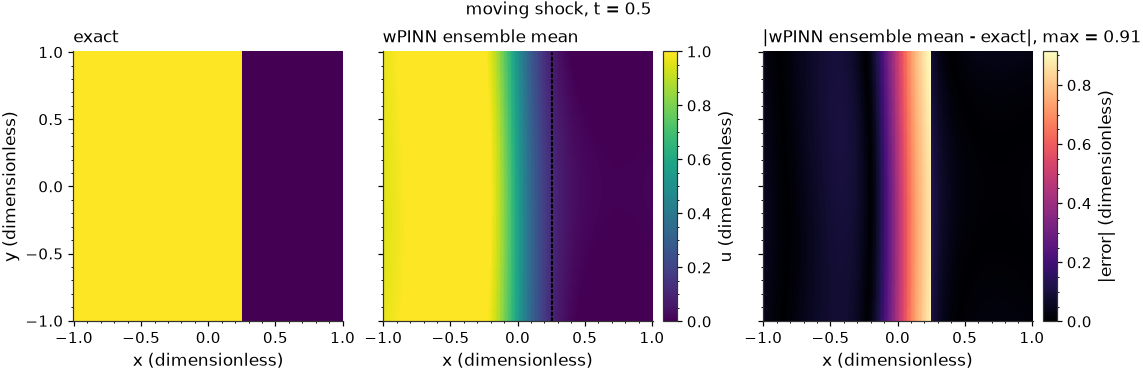

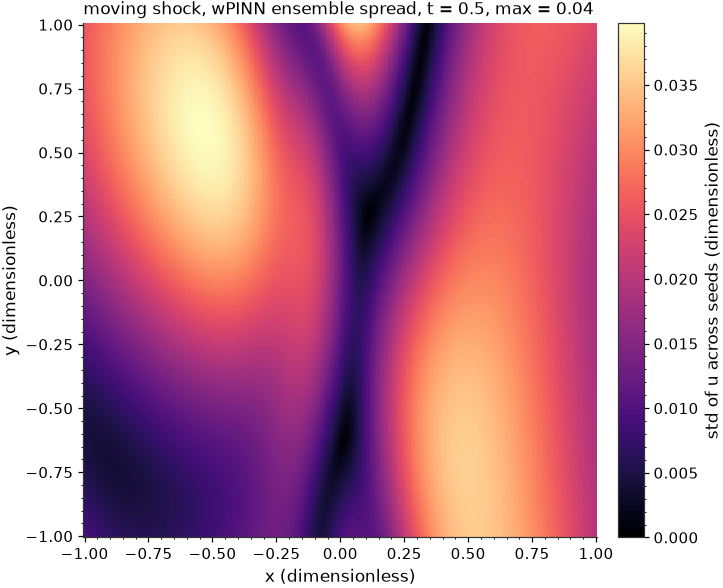

In [44]:
# Tres reentrenamientos de la wPINN del choque móvil con presupuesto reducido.
# Debe verse (a) el error de la red media por debajo de la media de los
# errores individuales, por la desigualdad triangular, y (b) que la dispersión
# NO vive en el frente: con este presupuesto los tres miembros suavizan y
# retrasan el choque igual (sesgo común) y sólo discrepan en las mesetas. El
# ensamble promedia varianza, no sesgo; por eso De Ryck lo combina con muchas
# más épocas y por eso el paper prefiere la difusión, que ataca el sesgo.
ensemble_smoke_problem = MOVING_SHOCK_PROBLEM


def train_one_weak_smoke_member() -> tuple[nn.Module, WeakTrainingHistory]:
    """Build and train one wPINN member with the smoke-test budget."""
    # Las redes se construyen DENTRO del entrenador y no fuera: así cada
    # miembro nace con pesos distintos bajo su semilla. Si se construyeran
    # antes, los tres compartirían la inicialización.
    network = MLP(
        n_input_features=ensemble_smoke_problem.n_spatial_dimensions + 1,
        n_output_features=1,
        hidden_layer_widths=[20] * 6,
        input_lower_bounds=ensemble_smoke_problem.space_time_lower_bounds,
        input_upper_bounds=ensemble_smoke_problem.space_time_upper_bounds,
    ).to(COMPUTE_DEVICE)
    test_network = TestFunctionNetwork(
        ensemble_smoke_problem,
        hidden_layer_widths=[10] * 4,
        range_transform=positive_by_softplus,
        window=polynomial_bump_window(ensemble_smoke_problem),
    ).to(COMPUTE_DEVICE)
    history = train_weak_pinn(
        network,
        test_network,
        ensemble_smoke_problem,
        n_epochs=300,
        n_interior_points=8000,
        n_initial_points=1000,
        n_boundary_points=1000,
        n_kruzhkov_constants=8,
        boundary_weight=10.0,
        residual_terms=paper_loss_terms(2, diffusion_coefficient=1e-3),
        log_every_n_epochs=300,
    )
    return network, history


ensemble_smoke_members = train_ensemble(train_one_weak_smoke_member, seeds=[0, 1, 2])

for key, value in ensemble_final_time_errors(ensemble_smoke_members, ensemble_smoke_problem).items():
    print(f"{key:32s} {value:.4f}")

plot_solution_comparison(
    EnsembleStatistic(ensemble_smoke_members, "mean"), ensemble_smoke_problem, method_label="wPINN ensemble mean"
)
plot_ensemble_spread(ensemble_smoke_members, ensemble_smoke_problem)
plt.show()


# Presupuesto de entrenamiento




In [45]:
from dataclasses import replace   # copias de un presupuesto cambiando un campo


@dataclass(frozen=True)
class TrainingBudget:
    """Everything that fixes the cost of one training run, for both methods.

    One object per experiment so that the strong PINN and the wPINN of a
    comparison are trained under exactly the same numbers, and so that a
    change of budget is one line instead of four call sites.
    """

    n_epochs: int
    n_interior_points: int
    n_initial_points: int
    n_boundary_points: int
    solution_layer_widths: tuple[int, ...]
    test_layer_widths: tuple[int, ...]
    n_kruzhkov_constants: int
    boundary_weight: float
    diffusion_coefficient: float
    learning_rate: float
    adversary_learning_rate: float


# Presupuesto de la wPINN del paper (sección 4): 1.6e4 puntos, 1000 épocas,
# red solución de 6 capas de 20, red test de 4 capas de 10, eps = 1e-3.
# Los puntos iniciales y de frontera no los fija el paper; se toma un 1/8 del
# interior para cada uno, que es la proporción de las pruebas de humo.
PAPER_WEAK_BUDGET = TrainingBudget(
    n_epochs=1000,
    n_interior_points=16_000,
    n_initial_points=2_000,
    n_boundary_points=2_000,
    solution_layer_widths=(20,) * 6,
    test_layer_widths=(10,) * 4,
    n_kruzhkov_constants=9,
    boundary_weight=10.0,
    diffusion_coefficient=1e-3,
    learning_rate=1e-3,
    adversary_learning_rate=1e-2,
)

# La PINN básica del paper usa 4e6 puntos y 15000 épocas. Los 4e6 puntos por
# época no caben en memoria con autograd de segundo orden en una GPU de
# escritorio, así que se conservan las 15000 épocas y los puntos de la wPINN:
# la PINN fuerte recibe 15 veces más pasos de gradiente, que es la ventaja que
# el paper le concede.
PAPER_STRONG_BUDGET = replace(PAPER_WEAK_BUDGET, n_epochs=15_000)


# Fábrica de redes




In [46]:
def build_solution_network(problem: ConservationLawProblem, budget: TrainingBudget) -> MLP:
    """A fresh solution network u_theta for the problem, on the compute device."""
    return MLP(
        n_input_features=problem.n_spatial_dimensions + 1,
        n_output_features=1,
        hidden_layer_widths=budget.solution_layer_widths,
        input_lower_bounds=problem.space_time_lower_bounds,
        input_upper_bounds=problem.space_time_upper_bounds,
    ).to(COMPUTE_DEVICE)


def build_test_network(problem: ConservationLawProblem, budget: TrainingBudget) -> TestFunctionNetwork:
    """A fresh De Ryck test network: softplus range and polynomial bump window."""
    # La phi de De Ryck y no la literal del paper: en la prueba de humo del
    # residual débil la literal dio una penalización seis veces mayor sobre
    # la misma red, señal de que sin phi >= 0 el residual castiga la
    # disipación legítima del choque.
    return TestFunctionNetwork(
        problem,
        hidden_layer_widths=budget.test_layer_widths,
        range_transform=positive_by_softplus,
        window=polynomial_bump_window(problem),
    ).to(COMPUTE_DEVICE)


# Empaquetamiento de entrenamientos con funciones




In [47]:
@dataclass(frozen=True)
class MethodResult:
    """What one method leaves behind on one problem: the trained network, its
    loss history, the errors at t = T and the wall-clock cost."""

    method_label: str
    network: nn.Module
    training_history: TrainingHistory | WeakTrainingHistory
    final_time_errors: dict[str, float]
    training_seconds: float


# Un "método" recibe (problema, presupuesto) y devuelve (red, historia). Las
# dos formulaciones se envuelven con esta firma para que la comparación
# los recorra en un bucle sin saber cuál es cuál.
TrainingMethod = Callable[[ConservationLawProblem, TrainingBudget], tuple[nn.Module, TrainingHistory | WeakTrainingHistory]]


def strong_pinn_method(problem: ConservationLawProblem, budget: TrainingBudget) -> tuple[nn.Module, TrainingHistory]:
    """Strong PINN with the budget's diffusion coefficient (paper: basic PINN + diffusion)."""
    network = build_solution_network(problem, budget)
    history = train_strong_pinn(
        network,
        problem,
        n_epochs=budget.n_epochs,
        n_interior_points=budget.n_interior_points,
        n_initial_points=budget.n_initial_points,
        n_boundary_points=budget.n_boundary_points,
        boundary_weight=budget.boundary_weight,
        diffusion_coefficient=budget.diffusion_coefficient,
        learning_rate=budget.learning_rate,
        log_every_n_epochs=budget.n_epochs,
    )
    return network, history


def weak_pinn_method(level: int, n_adversary_steps: int = 5) -> TrainingMethod:
    """wPINN with the paper's loss L0, L1 or L2, as a TrainingMethod.

    n_adversary_steps is the number of ascent steps on phi per epoch; the
    default 5 is the one used in every experiment so far.
    """
    def method(problem: ConservationLawProblem, budget: TrainingBudget) -> tuple[nn.Module, WeakTrainingHistory]:
        network = build_solution_network(problem, budget)
        test_network = build_test_network(problem, budget)
        history = train_weak_pinn(
            network,
            test_network,
            problem,
            n_epochs=budget.n_epochs,
            n_interior_points=budget.n_interior_points,
            n_initial_points=budget.n_initial_points,
            n_boundary_points=budget.n_boundary_points,
            n_kruzhkov_constants=budget.n_kruzhkov_constants,
            boundary_weight=budget.boundary_weight,
            residual_terms=paper_loss_terms(level, budget.diffusion_coefficient),
            # Los pasos de adversaria no van en el presupuesto porque son el
            # factor que el diagnóstico varía por separado.
            n_adversary_steps=n_adversary_steps,
            learning_rate=budget.learning_rate,
            adversary_learning_rate=budget.adversary_learning_rate,
            log_every_n_epochs=budget.n_epochs,
        )
        return network, history
    return method


def run_method(
    method_label: str, method: TrainingMethod, problem: ConservationLawProblem, budget: TrainingBudget, seed: int
) -> MethodResult:
    """Train one method on one problem under one seed and measure it."""
    # Misma semilla para todos los métodos de una comparación: misma
    # inicialización de la red solución y mismo sorteo de puntos, así la
    # diferencia entre métodos no se confunde con la varianza entre semillas.
    set_random_seed(seed)
    print(f"=== {problem.name}: {method_label} ===")
    start_time = time.perf_counter()
    network, history = method(problem, budget)
    training_seconds = time.perf_counter() - start_time
    return MethodResult(
        method_label=method_label,
        network=network,
        training_history=history,
        final_time_errors=final_time_errors(network, problem),
        training_seconds=training_seconds,
    )


# Comparación de métodos en un caso




In [48]:
def run_case_comparison(
    problem: ConservationLawProblem,
    weak_budget: TrainingBudget = PAPER_WEAK_BUDGET,
    strong_budget: TrainingBudget = PAPER_STRONG_BUDGET,
    seed: int = 0,
) -> list[MethodResult]:
    """Strong PINN + diffusion versus wPINN with L0, L1 and L2 on one problem."""
    results = [run_method("strong PINN + diffusion", strong_pinn_method, problem, strong_budget, seed)]
    for level in (0, 1, 2):
        results.append(run_method(f"wPINN L{level}", weak_pinn_method(level), problem, weak_budget, seed))
    return results


def largest_final_time_error(results: Sequence[MethodResult], problem: ConservationLawProblem) -> Optional[float]:
    """Max pointwise |network - exact| at t = T over all methods, or None without exact."""
    if problem.exact_solution is None:
        return None
    # Una sola escala de error para todos los paneles: si cada método usa la
    # suya, el peor método parece tan bueno como el mejor.
    return max(
        float(np.abs(snapshot.predicted - snapshot.exact).max())
        for snapshot in (evaluate_on_grid(result.network, problem, problem.final_time) for result in results)
    )


def report_case_comparison(results: Sequence[MethodResult], problem: ConservationLawProblem) -> None:
    """Print the error table and draw every method with a shared error scale."""
    print(f"\n{problem.name}: errors at t = {problem.final_time:.3g}")
    print(f"{'method':26s} {'rel. L1':>9s} {'rel. L2':>9s} {'seconds':>8s}")
    for result in results:
        l1 = result.final_time_errors.get("relative_l1", float("nan"))
        l2 = result.final_time_errors.get("relative_l2", float("nan"))
        print(f"{result.method_label:26s} {l1:9.4f} {l2:9.4f} {result.training_seconds:8.0f}")

    error_value_max = largest_final_time_error(results, problem)
    for result in results:
        plot_solution_comparison(
            result.network, problem, method_label=result.method_label, error_value_max=error_value_max
        )
    plt.show()


# Caso 1: rarefacción




=== rarefaction: strong PINN + diffusion ===
epoch  15000  total 1.187e-02  residual 9.077e-03  initial 1.422e-05  boundary 2.647e-04  [133 s]
=== rarefaction: wPINN L0 ===
epoch   1000  total 1.062e-01  weak 1.432e-02  adversary 1.324e-02  initial 3.472e-03  boundary 5.713e-03  [27 s]
=== rarefaction: wPINN L1 ===
epoch   1000  total 1.475e-01  weak 6.789e-03  adversary 5.321e-03  initial 8.547e-03  boundary 5.527e-03  [28 s]
=== rarefaction: wPINN L2 ===
epoch   1000  total 1.801e-01  weak 3.827e-02  adversary 2.310e-02  initial 8.513e-03  boundary 5.671e-03  [28 s]

rarefaction: errors at t = 2.5
method                       rel. L1   rel. L2  seconds
strong PINN + diffusion       0.1152    0.2189      133
wPINN L0                      0.2109    0.2878       27
wPINN L1                      0.2788    0.3924       28
wPINN L2                      0.2833    0.3905       28


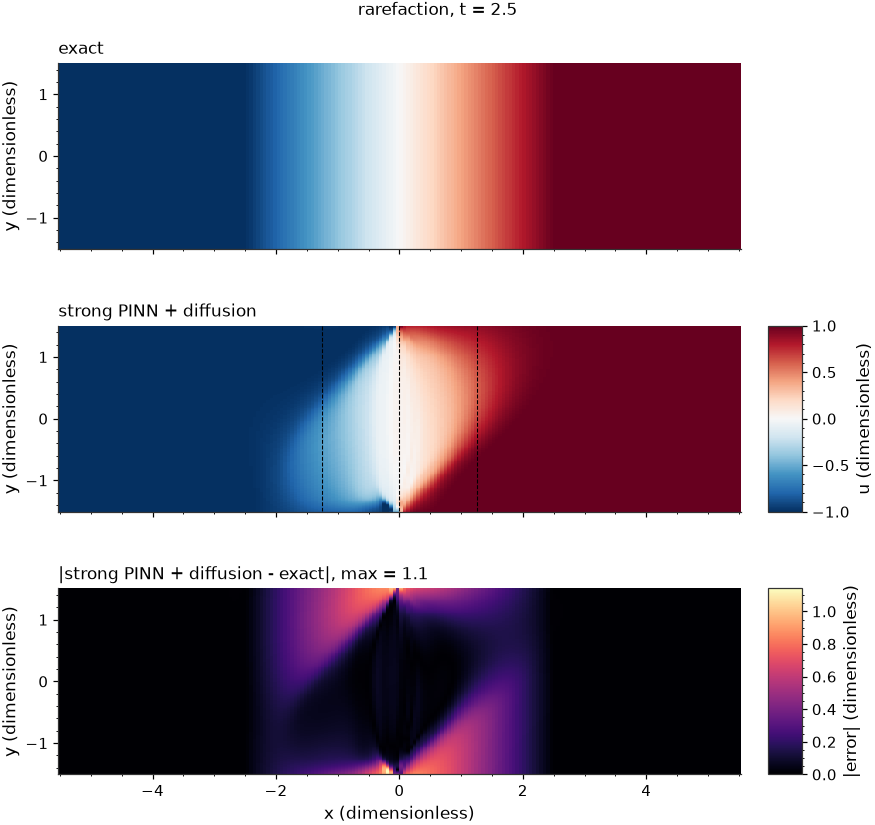

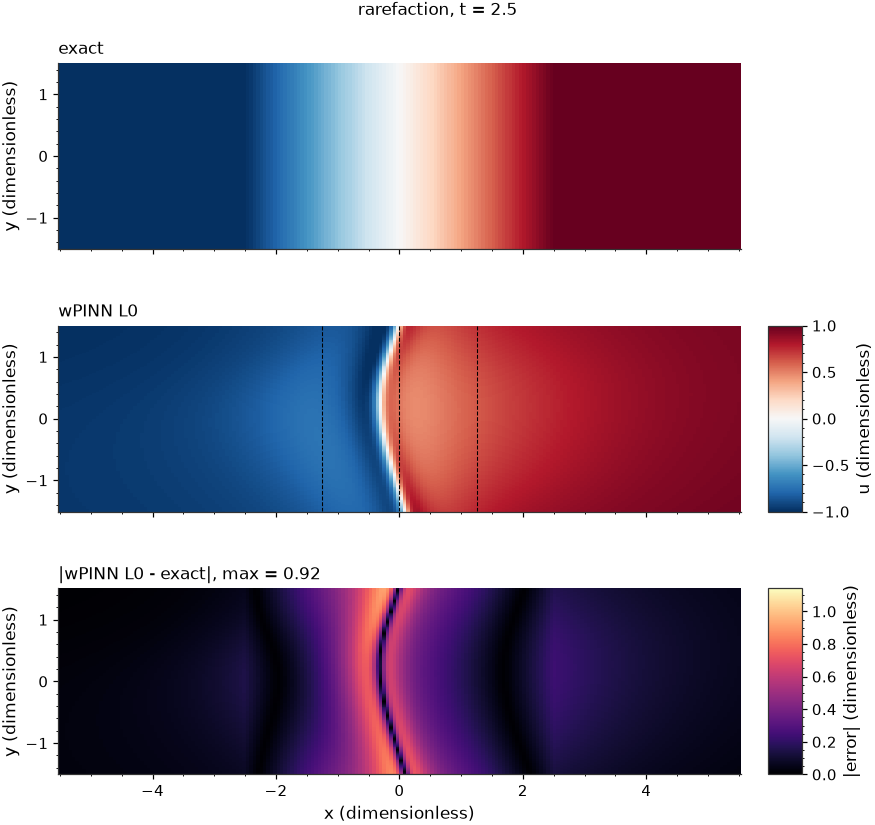

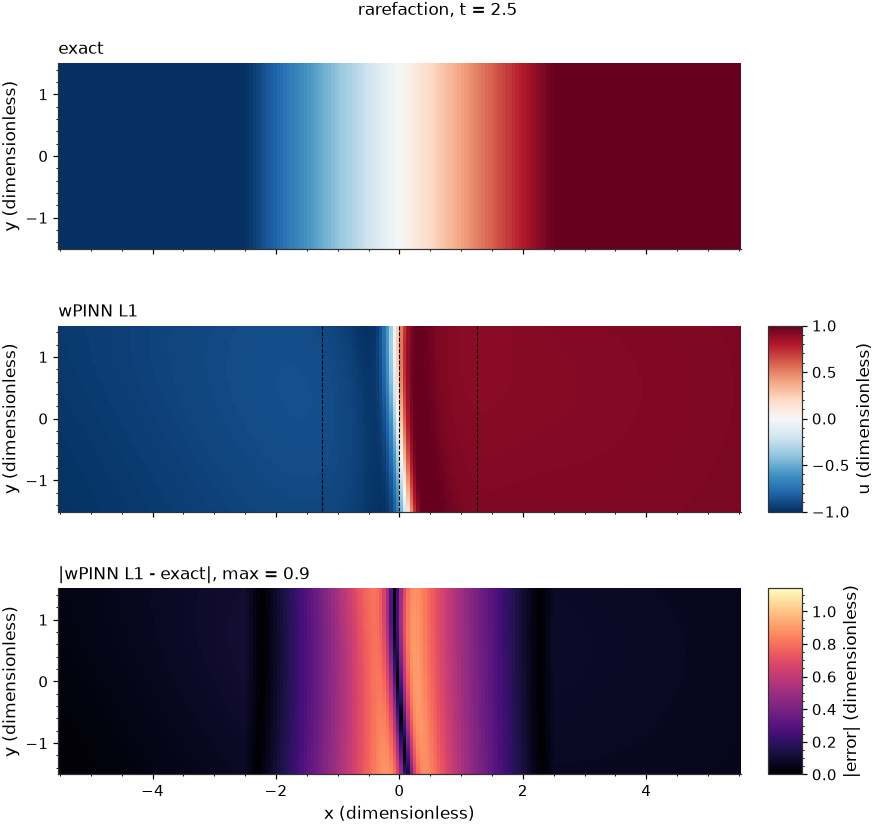

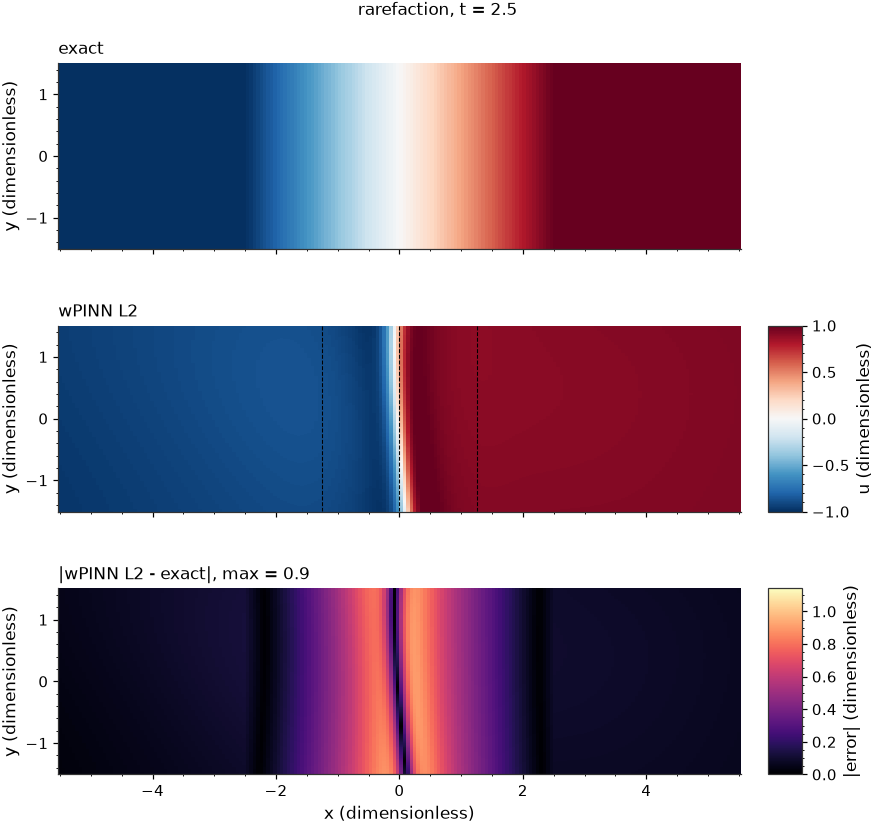

In [49]:
# La prueba clave del notebook. Con L0 (sólo Kruzhkov) se espera que aparezca
# el choque de expansión, que es una solución débil legítima pero no de
# entropía; L1 añade la tasa de entropía y L2 la difusión débil, y la pregunta
# es cuál de los dos lo corrige. La PINN fuerte con difusión es la referencia.
rarefaction_results = run_case_comparison(RAREFACTION_PROBLEM)
report_case_comparison(rarefaction_results, RAREFACTION_PROBLEM)


# Corte 1D en y fijo




In [50]:
def plot_profile_along_x(
    results: Sequence[MethodResult],
    problem: ConservationLawProblem,
    time: Optional[float] = None,
    y_value: float = 0.0,
) -> plt.Figure:
    """u versus x at a fixed y and time, every method on one axis, exact in black.

    For data that depend on x only (rarefaction, moving shock) this cut is
    the whole story: an expansion shock is a vertical jump at x = 0, the
    entropy fan is the ramp u = x / t. Colour maps hide that difference.
    """
    if time is None:
        time = problem.final_time
    figure, axis = plt.subplots()

    # Se dibujan las curvas de los métodos y, una sola vez, la exacta. La malla
    # es la misma para todos (evaluate_on_grid es determinista), así que la
    # fila de y más cercana a y_value es la misma en cada snapshot.
    exact_drawn = False
    # Estilos de línea distintos y no sólo colores: la figura debe leerse
    # también impresa en gris.
    line_styles = ["-", "--", "-.", ":"]
    for result, line_style in zip(results, line_styles * (len(results) // len(line_styles) + 1)):
        snapshot = evaluate_on_grid(result.network, problem, time)
        row = int(np.argmin(np.abs(snapshot.y_axis - y_value)))
        if snapshot.exact is not None and not exact_drawn:
            axis.plot(snapshot.x_axis, snapshot.exact[row], color="black", linewidth=2.0, label="exact")
            exact_drawn = True
        axis.plot(snapshot.x_axis, snapshot.predicted[row], linestyle=line_style, label=result.method_label)

    axis.set_xlabel("x (dimensionless)")
    axis.set_ylabel("u (dimensionless)")
    axis.set_title(f"{problem.name.replace('_', ' ')}, cut at y = {y_value:.2g}, t = {time:.3g}")
    axis.legend()
    return figure


# Diagnóstico de la rarefacción: épocas y pasos de adversaria




=== rarefaction: wPINN L1, 5000 epochs, 5 steps ===
epoch   5000  total 6.626e-02  weak 1.645e-02  adversary 1.145e-02  initial 1.697e-03  boundary 3.284e-03  [136 s]
=== rarefaction: wPINN L1, 1000 epochs, 20 steps ===
epoch   1000  total 1.925e+01  weak 2.246e-02  adversary 2.161e-02  initial 9.654e-01  boundary 9.570e-01  [85 s]
=== rarefaction: wPINN L1, 5000 epochs, 20 steps ===
epoch   5000  total 1.285e+01  weak 7.581e-02  adversary 5.755e-02  initial 6.615e-01  boundary 6.164e-01  [427 s]

rarefaction: errors at t = 2.5
method                       rel. L1   rel. L2  seconds
wPINN L1                      0.2788    0.3924       28
wPINN L1, 5000 epochs, 5 steps    0.2406    0.3476      136
wPINN L1, 1000 epochs, 20 steps    0.9733    0.9733       85
wPINN L1, 5000 epochs, 20 steps    0.7493    0.7479      427


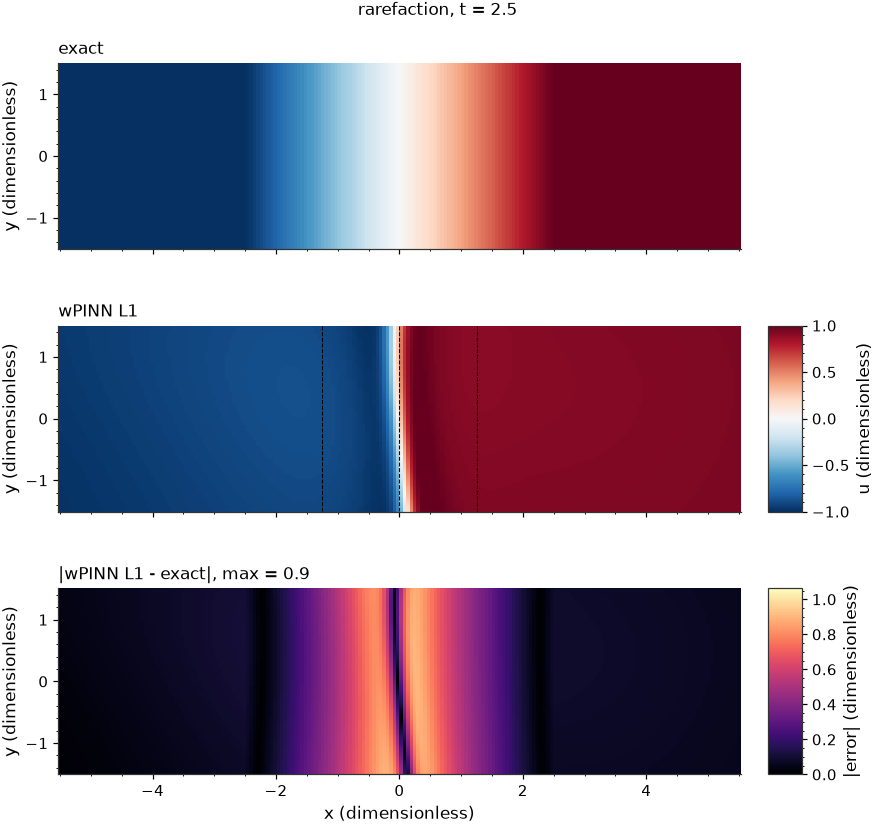

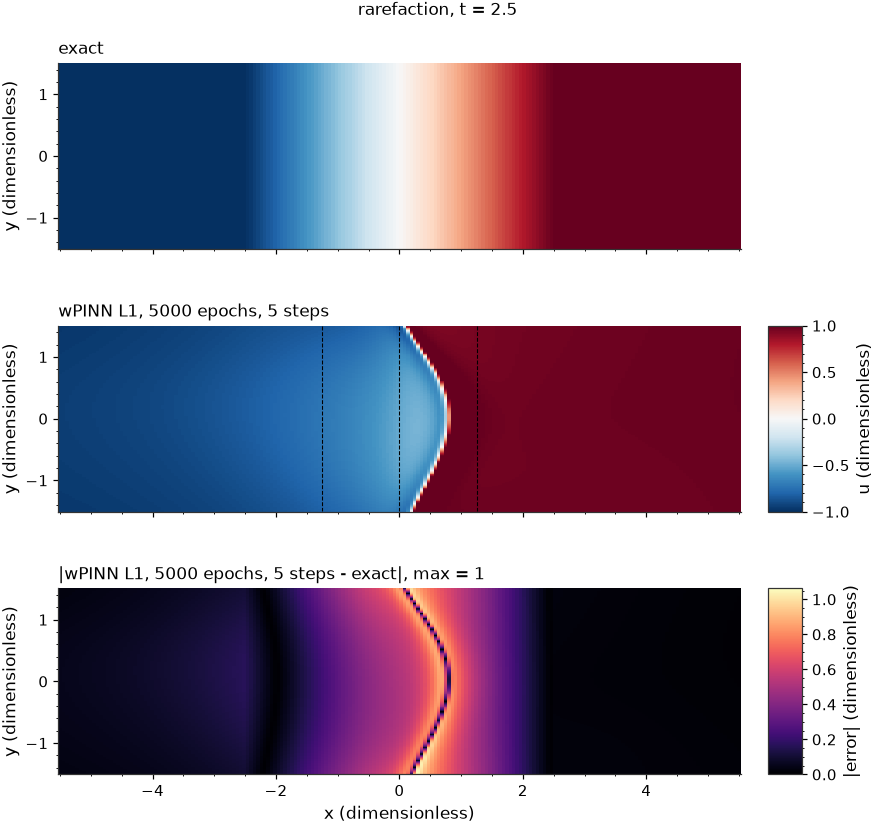

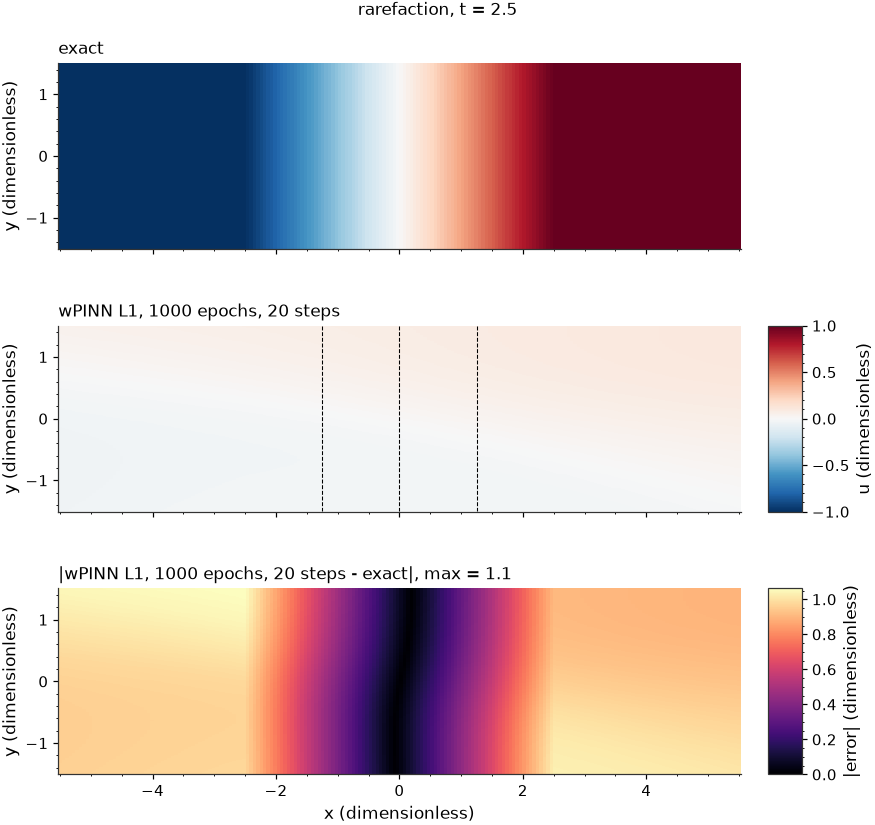

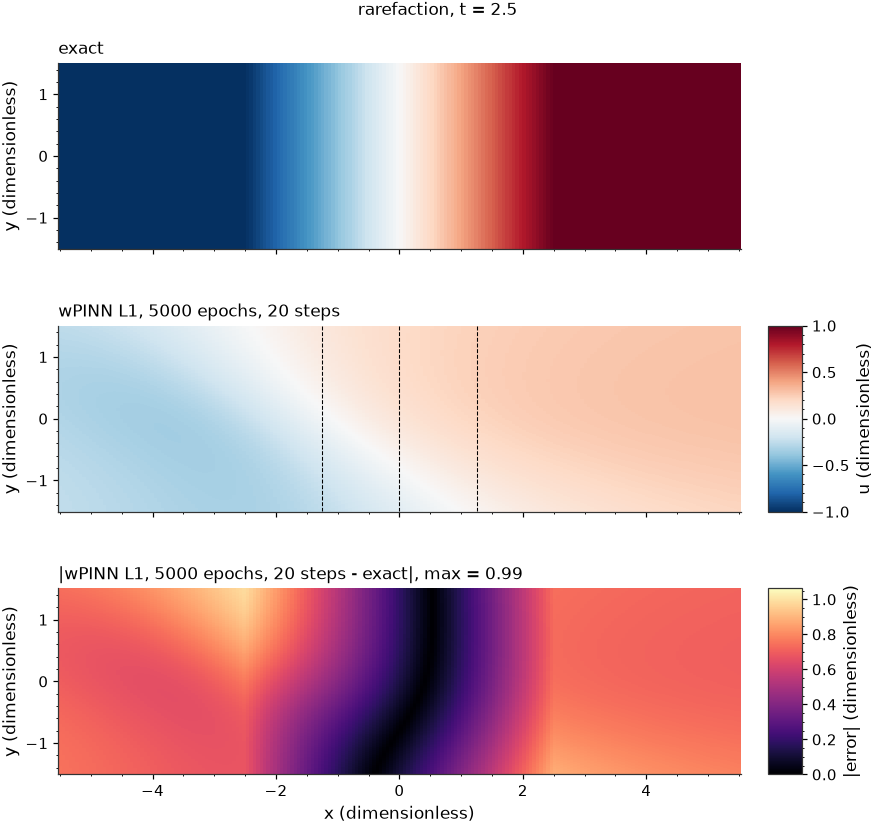

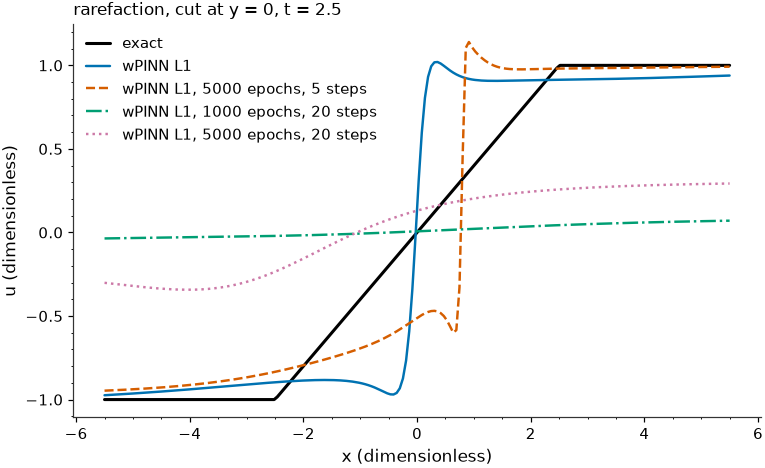

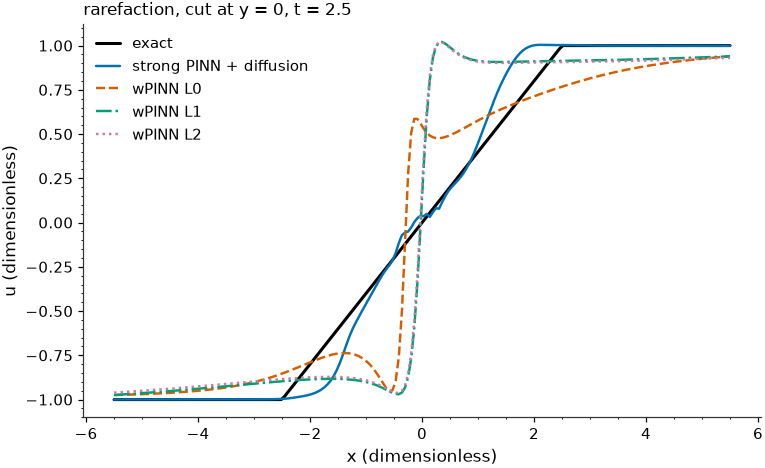

In [51]:
@dataclass(frozen=True)
class DiagnosticVariant:
    """One knob setting of the wPINN training to isolate its effect."""

    label: str
    budget: TrainingBudget
    n_adversary_steps: int


# Un factor a la vez respecto al presupuesto del paper (1000 épocas, 5 pasos):
#   - más épocas: De Ryck entrena 5000; en 1D el término de entropía necesitó
#     ese orden para vencer al choque de expansión.
#   - más pasos de adversaria: con 5 pasos y reinicio cada época, phi apenas
#     alcanza a encontrar la violación antes de que u se mueva.
#   - los dos juntos: si sólo esta corrige el abanico, el método funciona pero
#     el presupuesto del paper no alcanza.
RAREFACTION_DIAGNOSTIC_VARIANTS = [
    DiagnosticVariant("5000 epochs, 5 steps", replace(PAPER_WEAK_BUDGET, n_epochs=5000), n_adversary_steps=5),
    DiagnosticVariant("1000 epochs, 20 steps", PAPER_WEAK_BUDGET, n_adversary_steps=20),
    DiagnosticVariant("5000 epochs, 20 steps", replace(PAPER_WEAK_BUDGET, n_epochs=5000), n_adversary_steps=20),
]


def run_weak_pinn_diagnostic(
    problem: ConservationLawProblem,
    level: int,
    variants: Sequence[DiagnosticVariant],
    seed: int = 0,
) -> list[MethodResult]:
    """Train the wPINN with loss L{level} once per variant, same seed for all."""
    results = []
    for variant in variants:
        method = weak_pinn_method(level, n_adversary_steps=variant.n_adversary_steps)
        results.append(run_method(f"wPINN L{level}, {variant.label}", method, problem, variant.budget, seed))
    return results


# L1 y no L2: es el término que el paper presenta como el que impone la
# entropía; la difusión de L2 se estudia aparte. La corrida base del paper
# (1000 épocas, 5 pasos) ya está en rarefaction_results[2] y se reutiliza.
rarefaction_diagnostic_results = [rarefaction_results[2]] + run_weak_pinn_diagnostic(
    RAREFACTION_PROBLEM, level=1, variants=RAREFACTION_DIAGNOSTIC_VARIANTS
)
report_case_comparison(rarefaction_diagnostic_results, RAREFACTION_PROBLEM)
plot_profile_along_x(rarefaction_diagnostic_results, RAREFACTION_PROBLEM)
plot_profile_along_x(rarefaction_results, RAREFACTION_PROBLEM)
plt.show()
